In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Simple domains — every model, every feature-less domain

Batch of 2026-10-12 (`data/simple_domains/`): **10 domains × 24 models** (qwen / gemma / olmo × 4 sizes ×
instruct and base) = 240 runs. Frame `bare`, no contract, PMI off. Instruct models use the 43 `options`
templates, base models the 25 `pretrained` ones. Nir's list item 2: does each model have a **stable**
preference on items with no features?

Per run, for items x, y and template t: `m(x,y)` = score of slot 1 − score of slot 2 with x in slot 1
(log-odds of answering "1" over "2"). **`D(x,y) = (m(x,y) − m(y,x)) / 2`** removes the slot bias.
An item's utility = its **Borda score** = mean D against the other items (over templates).

Measures, one table row per (model, domain):

- **template agreement (Kendall's W)** — rank the items separately under each template; W = how much
  the templates agree. 1 = every template gives the same order, 0 = no agreement.
- **position-driven %** — share of (pair, template) where the model picks the **same slot** in both
  orders, so the answer follows the position, not the item. 0 = never, 100 = always.
- **BT vs Borda** — Spearman between a soft Bradley-Terry fit (`fit_BT_soft`, src) and the Borda order.
- **top item**, and the full order.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from scipy.stats import spearmanr, rankdata
from src.pref_models import fit_BT_soft

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/simple_domains"
os.makedirs(FIGDIR, exist_ok=True)

BASE = "data/simple_domains"
DOMAINS = ["colors", "foods", "cars", "stocks", "laptop_brands", "laptops",
           "literature_genres", "ai_companies", "travel_destinations", "beverages"]
SIZES = {"qwen": ["0.5", "7", "32", "72"], "gemma": ["1", "4", "12", "27"], "olmo": ["1", "7", "13", "32"]}
MODELS = [(f + v, s) for v in ("", "-pt") for f in SIZES for s in SIZES[f]]        # 12 instruct, then 12 base
MNAME = {m: f"{m[0]}-{m[1]}B" for m in MODELS}


def tensor(d, items):
    """M[t, i, j] = m(item i in slot 1, item j in slot 2) under template t."""
    T_ = sorted(d.template_idx.unique())
    ix = {x: i for i, x in enumerate(items)}
    M = np.full((len(T_), len(items), len(items)), np.nan)
    M[[T_.index(t) for t in d.template_idx], d.a_item.map(ix), d.b_item.map(ix)] = d.score_a.values - d.score_b.values
    return M


RUNS = {}            # (family, size, domain) -> dict(items, d, M, cfg)
audit = []
for r in sorted(os.listdir(BASE)):
    cf, sc = f"{BASE}/{r}/config.json", f"{BASE}/{r}/scores.csv"
    if not (os.path.isfile(cf) and os.path.isfile(sc)):
        continue
    c = json.load(open(cf))
    d = pd.read_csv(sc)
    items = sorted(set(d.a_item) | set(d.b_item))
    n, T = len(items), len(c["templates"])
    k = (c["model_family"], str(c["model_size"]), c["alternatives"])
    assert k not in RUNS, f"two complete runs for {k}"
    RUNS[k] = dict(items=items, M=tensor(d, items), cfg=c)
    audit.append({"run": r, "rows": len(d), "expected": n * (n - 1) * T,
                  "dup": int(d.duplicated(["template_idx", "a_item", "b_item"]).sum()),
                  "NaN": int(d[["score_a", "score_b"]].isna().sum().sum())})
AUD = pd.DataFrame(audit)
assert (AUD.rows == AUD.expected).all() and (AUD.dup == 0).all() and (AUD.NaN == 0).all()
missing = [(m, dom) for m in MODELS for dom in DOMAINS if (*m, dom) not in RUNS]
print(f"{len(RUNS)} runs, all complete; missing: {missing or 'none'}")


def pale(color, t=0.62):
    c, w = np.array(to_rgb(color)), np.ones(3)
    return tuple(c + (w - c) * t)


240 runs, all complete; missing: none


## Compute every measure

One row per (model, domain), saved to `figs/simple_domains/simple_domains_table.csv`.

In [3]:
def kendall_w(R):
    """R[t, i] = rank of item i under template t. Kendall's W, no tie correction."""
    m, n = R.shape
    S = ((R.sum(0) - m * (n + 1) / 2) ** 2).sum()
    return 12 * S / (m ** 2 * (n ** 3 - n))


rows, BORDA, BT = [], {}, {}
for (fam, size, dom), R in RUNS.items():
    M, items = R["M"], R["items"]
    n = len(items)
    D = (M - M.transpose(0, 2, 1)) / 2
    off = ~np.eye(n, dtype=bool)
    borda_t = np.array([D[t][off].reshape(n, n - 1).mean(1) for t in range(len(D))])   # [t, item]
    borda = pd.Series(borda_t.mean(0), index=items).sort_values(ascending=False)
    BORDA[(fam, size, dom)] = borda
    iu = np.triu_indices(n, 1)
    same_slot = (M[:, iu[0], iu[1]] > 0) == (M[:, iu[1], iu[0]] > 0)
    d = pd.DataFrame({"item_a": [items[i] for i in np.nonzero(off)[0]] * len(M),
                      "item_b": [items[j] for j in np.nonzero(off)[1]] * len(M)})
    d["score_a"] = np.concatenate([M[t][off] for t in range(len(M))])
    d["score_b"] = 0.0
    bt, _ = fit_BT_soft(d, items)
    bt = bt.set_index("Item").BT_Score
    BT[(fam, size, dom)] = bt
    rows.append({"family": fam.replace("-pt", ""), "variant": "pretrained" if fam.endswith("-pt") else "aligned",
                 "size_B": float(size), "model": MNAME[(fam, size)], "domain": dom, "n_items": n, "n_templates": len(M),
                 "template_agreement_W": kendall_w(np.array([rankdata(-b) for b in borda_t])),
                 "position_driven_pct": 100 * same_slot.mean(),
                 "bt_vs_borda_spearman": spearmanr(bt[borda.index], borda)[0],
                 "borda_spread": borda.iloc[0] - borda.iloc[-1],
                 "top_item": borda.index[0], "second_item": borda.index[1],
                 "order": " > ".join(borda.index)})
TAB = pd.DataFrame(rows)
TAB["_m"] = [MODELS.index((f + ("-pt" if v == "pretrained" else ""), f"{s:g}")) for f, v, s in zip(TAB.family, TAB.variant, TAB.size_B)]
TAB["_d"] = TAB.domain.map(DOMAINS.index)
TAB = TAB.sort_values(["_m", "_d"]).drop(columns=["_m", "_d"]).reset_index(drop=True)
TAB.to_csv(os.path.join(FIGDIR, "simple_domains_table.csv"), index=False, float_format="%.4f")
print(TAB.groupby("variant")[["template_agreement_W", "position_driven_pct", "bt_vs_borda_spearman"]].describe().T.round(2).to_string())

variant                     aligned  pretrained
template_agreement_W count   120.00      120.00
                     mean      0.88        0.64
                     std       0.10        0.22
                     min       0.37        0.12
                     25%       0.84        0.50
                     50%       0.90        0.70
                     75%       0.94        0.79
                     max       1.00        0.93
position_driven_pct  count   120.00      120.00
                     mean     55.03       80.40
                     std      25.19       16.44
                     min       4.26       41.33
                     25%      32.78       68.74
                     50%      54.11       84.76
                     75%      76.28       95.48
                     max      98.78      100.00
bt_vs_borda_spearman count   120.00      120.00
                     mean      0.96        0.97
                     std       0.07        0.06
                     min       0.68     

In [4]:
# Excel export: one row per (model, domain, item). bt = soft-BT weight (sums to 0 per run), bt_norm = bt / (max - min)
# as on the x axis of R / R5, borda = mean de-biased margin vs every other item. Run-level measures repeated per row.
import shutil
long = []
for (fam, size, dom), bt in BT.items():
    borda = BORDA[(fam, size, dom)]
    long.append(pd.DataFrame({"model": MNAME[(fam, size)], "family": fam.replace("-pt", ""),
                              "variant": "pretrained" if fam.endswith("-pt") else "aligned", "size_B": float(size),
                              "domain": dom, "item": bt.index, "bt": bt.values, "bt_norm": (bt / (bt.max() - bt.min())).values,
                              "bt_rank": bt.rank(ascending=False, method="min").values.astype(int), "borda": borda[bt.index].values,
                              "borda_rank": borda.rank(ascending=False, method="min")[bt.index].values.astype(int)}))
LONG = pd.concat(long).merge(TAB[["model", "domain", "n_items", "n_templates", "template_agreement_W",
                                  "position_driven_pct", "bt_vs_borda_spearman"]], on=["model", "domain"])
LONG = LONG.sort_values(["variant", "family", "size_B", "domain", "bt_rank"]).reset_index(drop=True)
LONG.to_csv(os.path.join(FIGDIR, "simple_domains_bt.csv"), index=False, float_format="%.4f", encoding="utf-8-sig")
shutil.copy(os.path.join(FIGDIR, "simple_domains_bt.csv"), "/mnt/c/Users/User1/Downloads/")   # Excel can't always open WSL files
print(LONG.shape)
LONG.head(8)

(1704, 16)


,model,family,variant,size_B,domain,item,bt,bt_norm,bt_rank,borda,borda_rank,n_items,n_templates,template_agreement_W,position_driven_pct,bt_vs_borda_spearman
0,gemma-1B,gemma,aligned,1.0,ai_companies,Anthropic,1.100732,0.718122,1,9.283414,1,7,43,0.725914,71.760797,0.857143
1,gemma-1B,gemma,aligned,1.0,ai_companies,DeepSeek,0.358786,0.234074,2,1.828449,2,7,43,0.725914,71.760797,0.857143
2,gemma-1B,gemma,aligned,1.0,ai_companies,Allen Institute for AI,-0.058397,-0.038099,3,-0.533188,4,7,43,0.725914,71.760797,0.857143
3,gemma-1B,gemma,aligned,1.0,ai_companies,OpenAI,-0.138384,-0.090282,4,-0.055418,3,7,43,0.725914,71.760797,0.857143
4,gemma-1B,gemma,aligned,1.0,ai_companies,Google,-0.411116,-0.268214,5,-3.650982,7,7,43,0.725914,71.760797,0.857143
5,gemma-1B,gemma,aligned,1.0,ai_companies,Meta,-0.419562,-0.273724,6,-3.238814,5,7,43,0.725914,71.760797,0.857143
6,gemma-1B,gemma,aligned,1.0,ai_companies,Alibaba,-0.432060,-0.281878,7,-3.633461,6,7,43,0.725914,71.760797,0.857143
7,gemma-1B,gemma,aligned,1.0,beverages,Wine,0.258222,0.365881,1,2.603439,1,7,43,0.701422,85.049834,0.750000


In [5]:
# Colour = family, shade = size (4 fixed shades per family, light = smallest). Base models: hatched bars.
FAM_COL = {"qwen": "#4a3aa7", "gemma": "#eb6834", "olmo": "#1baf7a"}
SHADES = [0.62, 0.42, 0.2, 0.0]                                   # mix with white, smallest -> largest size


def model_color(m):
    fam = m[0].replace("-pt", "")
    t = SHADES[SIZES[fam].index(m[1])]
    c, w = np.array(to_rgb(FAM_COL[fam])), np.ones(3)
    return tuple(c + (w - c) * t)


def is_base(m):
    return m[0].endswith("-pt")


TAB["key"] = [(f + ("-pt" if v == "pretrained" else ""), f"{s:g}") for f, v, s in zip(TAB.family, TAB.variant, TAB.size_B)]


def bars(val, ylim, ylabel, title, fname, ref=None):
    """Left: one bar per model = mean over the 10 domains ± SE. Right: one bar per domain = mean over the
    12 models ± SE, instruct and base side by side."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.25, 1]}, sharey=True)
    g = TAB.groupby("key")[val]
    xs = [i + (i // 4) * 0.6 + (1.2 if i >= 12 else 0) for i in range(len(MODELS))]   # gaps between families and instruct | base
    for x, m in zip(xs, MODELS):
        v = g.get_group(m)
        a1.bar(x, v.mean(), 0.8, yerr=v.std(ddof=1) / np.sqrt(len(v)), color=model_color(m), capsize=2,
               error_kw={"lw": 0.9, "ecolor": INK_MUTED}, hatch="////" if is_base(m) else None,
               edgecolor=SURFACE if not is_base(m) else "white", lw=0, zorder=2)
    a1.set_xticks(xs, [f"{m[1]}B" for m in MODELS], fontsize=8)
    for k, lab in [(1.5, "qwen"), (6.1, "gemma"), (10.7, "olmo")]:
        for off in (0, xs[12] - xs[0]):
            a1.text(k + off, -0.13, lab, transform=a1.get_xaxis_transform(), ha="center", fontsize=8.5,
                    color=FAM_COL[lab], fontweight="bold")
    a1.text((xs[0] + xs[11]) / 2, 1.02, "instruct", transform=a1.get_xaxis_transform(), ha="center", fontweight="bold")
    a1.text((xs[12] + xs[23]) / 2, 1.02, "base (hatched)", transform=a1.get_xaxis_transform(), ha="center", fontweight="bold")
    a1.set_ylabel(ylabel)
    a1.set_title("per model: mean over the 10 domains ± SE", loc="left", fontsize=9.5, color=INK_MUTED, pad=18)

    x = np.arange(len(DOMAINS))
    for j, (var, lab) in enumerate([("aligned", "instruct"), ("pretrained", "base")]):
        g2 = TAB[TAB.variant == var].groupby("domain")[val]
        mu = g2.mean()[DOMAINS]
        se = (g2.std(ddof=1) / np.sqrt(g2.size()))[DOMAINS]
        a2.bar(x + (j - 0.5) * 0.38, mu, 0.36, yerr=se, color=["#52514e", "#b5b3ad"][j], capsize=2,
               error_kw={"lw": 0.9, "ecolor": INK_MUTED}, label=f"{lab} (12 models)", zorder=2)
    a2.set_xticks(x, [d.replace("_", " ") for d in DOMAINS], fontsize=8, rotation=30, ha="right", rotation_mode="anchor")
    a2.legend(frameon=False, fontsize=8.5, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.12))
    a2.set_title("per domain: mean over the 12 models ± SE", loc="left", fontsize=9.5, color=INK_MUTED, pad=18)
    for ax in (a1, a2):
        ax.grid(True, axis="y", color="#e8e7e3")
        ax.set_ylim(*ylim)
        if ref is not None:
            ax.axhline(ref, color=INK_MUTED, lw=0.9, ls=":", zorder=1)
    fig.suptitle(title, x=0.01, y=1.04, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()

## S1 — are the preferences stable across templates?

Kendall's W of the per-template orders (1 = every template gives the same order). Instruct models
use 43 templates, base models 25.

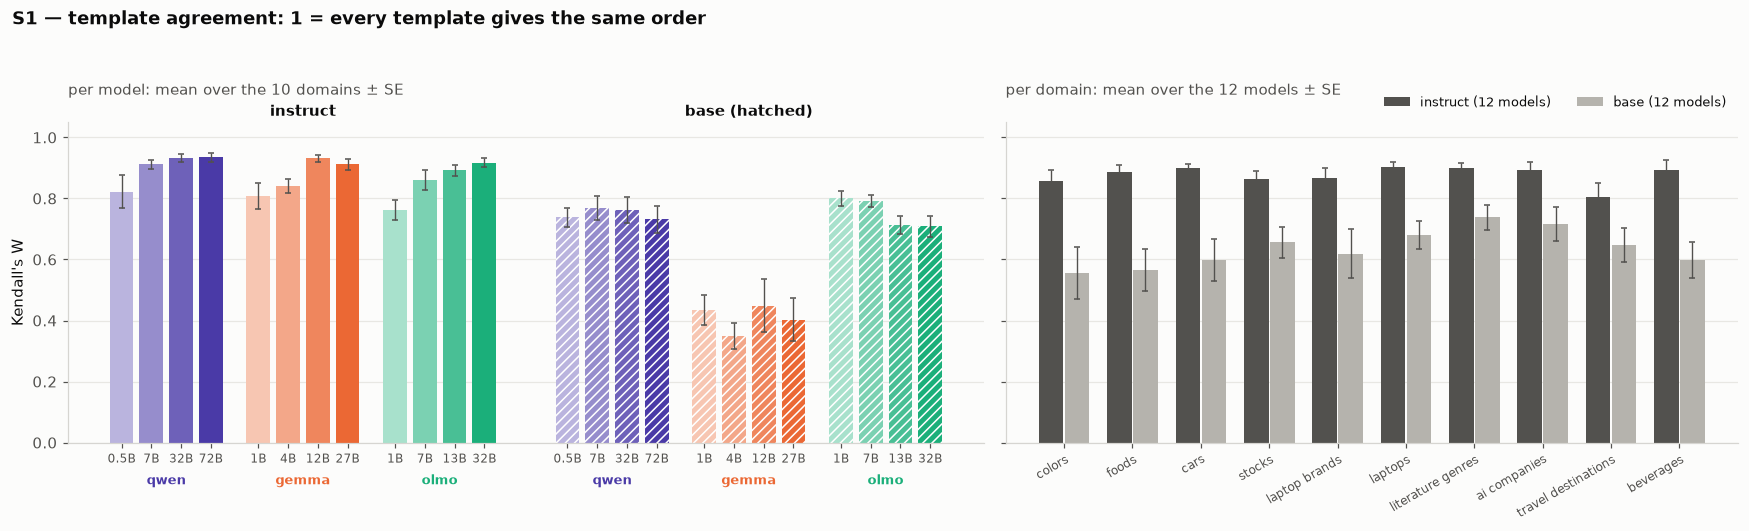

In [6]:
bars("template_agreement_W", (0, 1.05), "Kendall's W", "S1 — template agreement: 1 = every template gives the same order", "S1_template_agreement.png")

## S2 — how much of the answer is position, not item?

% of (pair, template) where the model picks the same slot in both orders. 100% = a model that always
answers by position; 0% = always follows the item; 50% (dotted line) = what random answers give. D removes this bias from the Borda score, but a high
value means less of the answer is about the items.

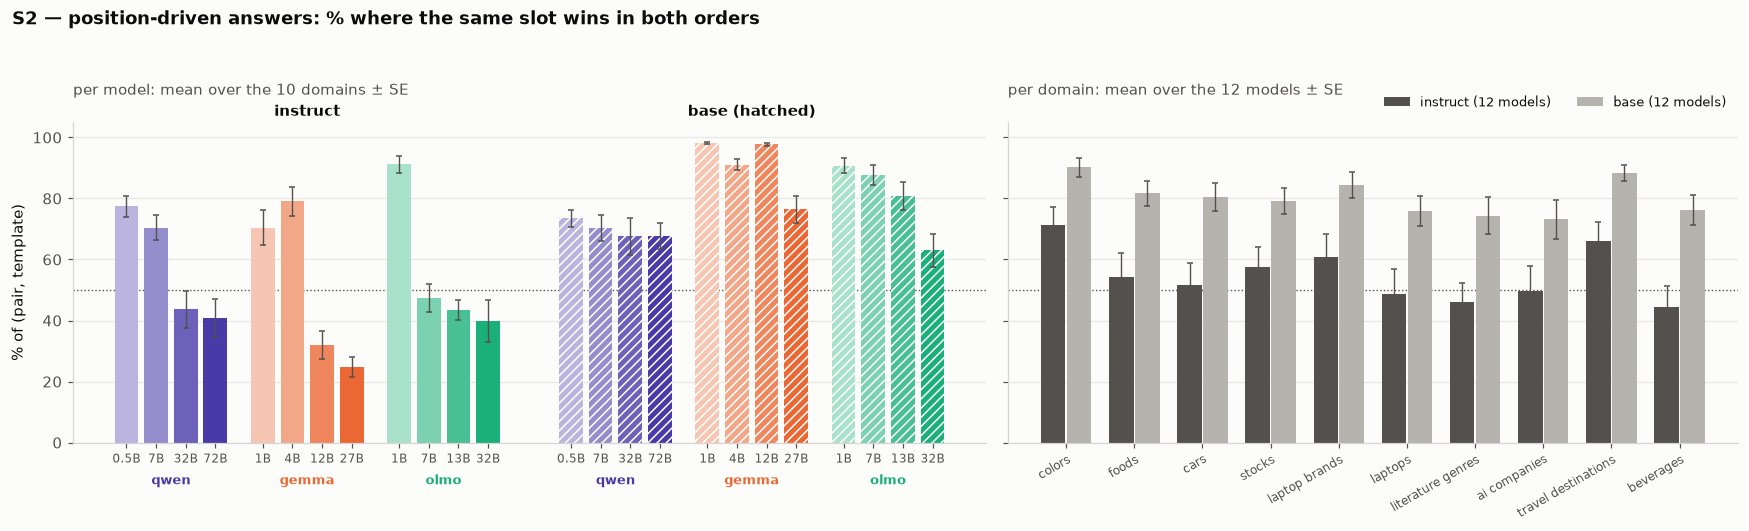

In [7]:
bars("position_driven_pct", (0, 105), "% of (pair, template)", "S2 — position-driven answers: % where the same slot wins in both orders", "S2_position_driven.png", ref=50)

## S3 — BT vs Borda

Spearman between the soft Bradley-Terry fit and the Borda order. Near 1 everywhere = the two give the
same ranking, so either can be reported.

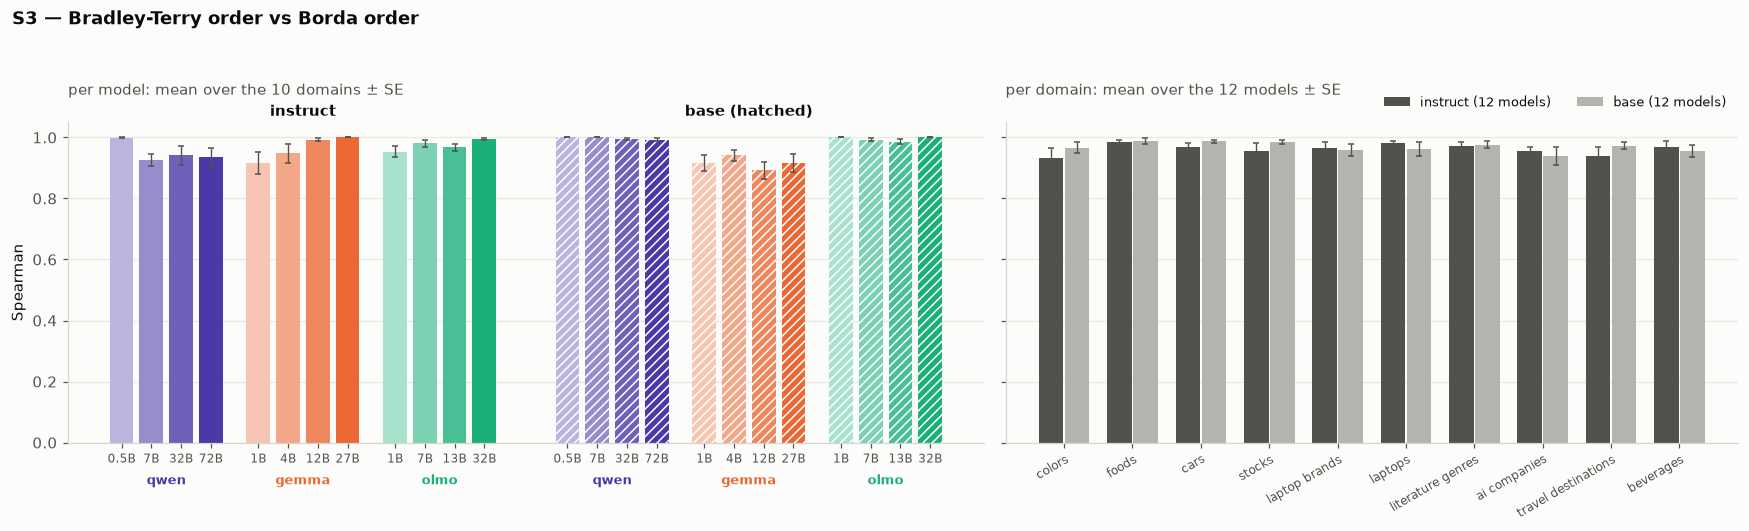

In [8]:
bars("bt_vs_borda_spearman", (0, 1.05), "Spearman", "S3 — Bradley-Terry order vs Borda order", "S3_bt_vs_borda.png")

## R — the orders themselves, all 10 domains

One row per item, ordered by the mean over the 12 instruct models (most liked on top). One dot per model:
**colour = family**, **shade = size** (light = smallest, dark = largest); within a row the dots are spread a
little by family (qwen above, olmo below) so they do not hide each other. **Black tick = the mean** over
the 12 models of that panel. Left of each pair: instruct; right: base.

x = the **normalised BT weight**: the item's soft-BT weight divided by that model's range (best item −
worst item), so every model spans 1 and a loud model does not hide a quiet one. Tight dots = the models
agree on the item; spread dots = they do not.

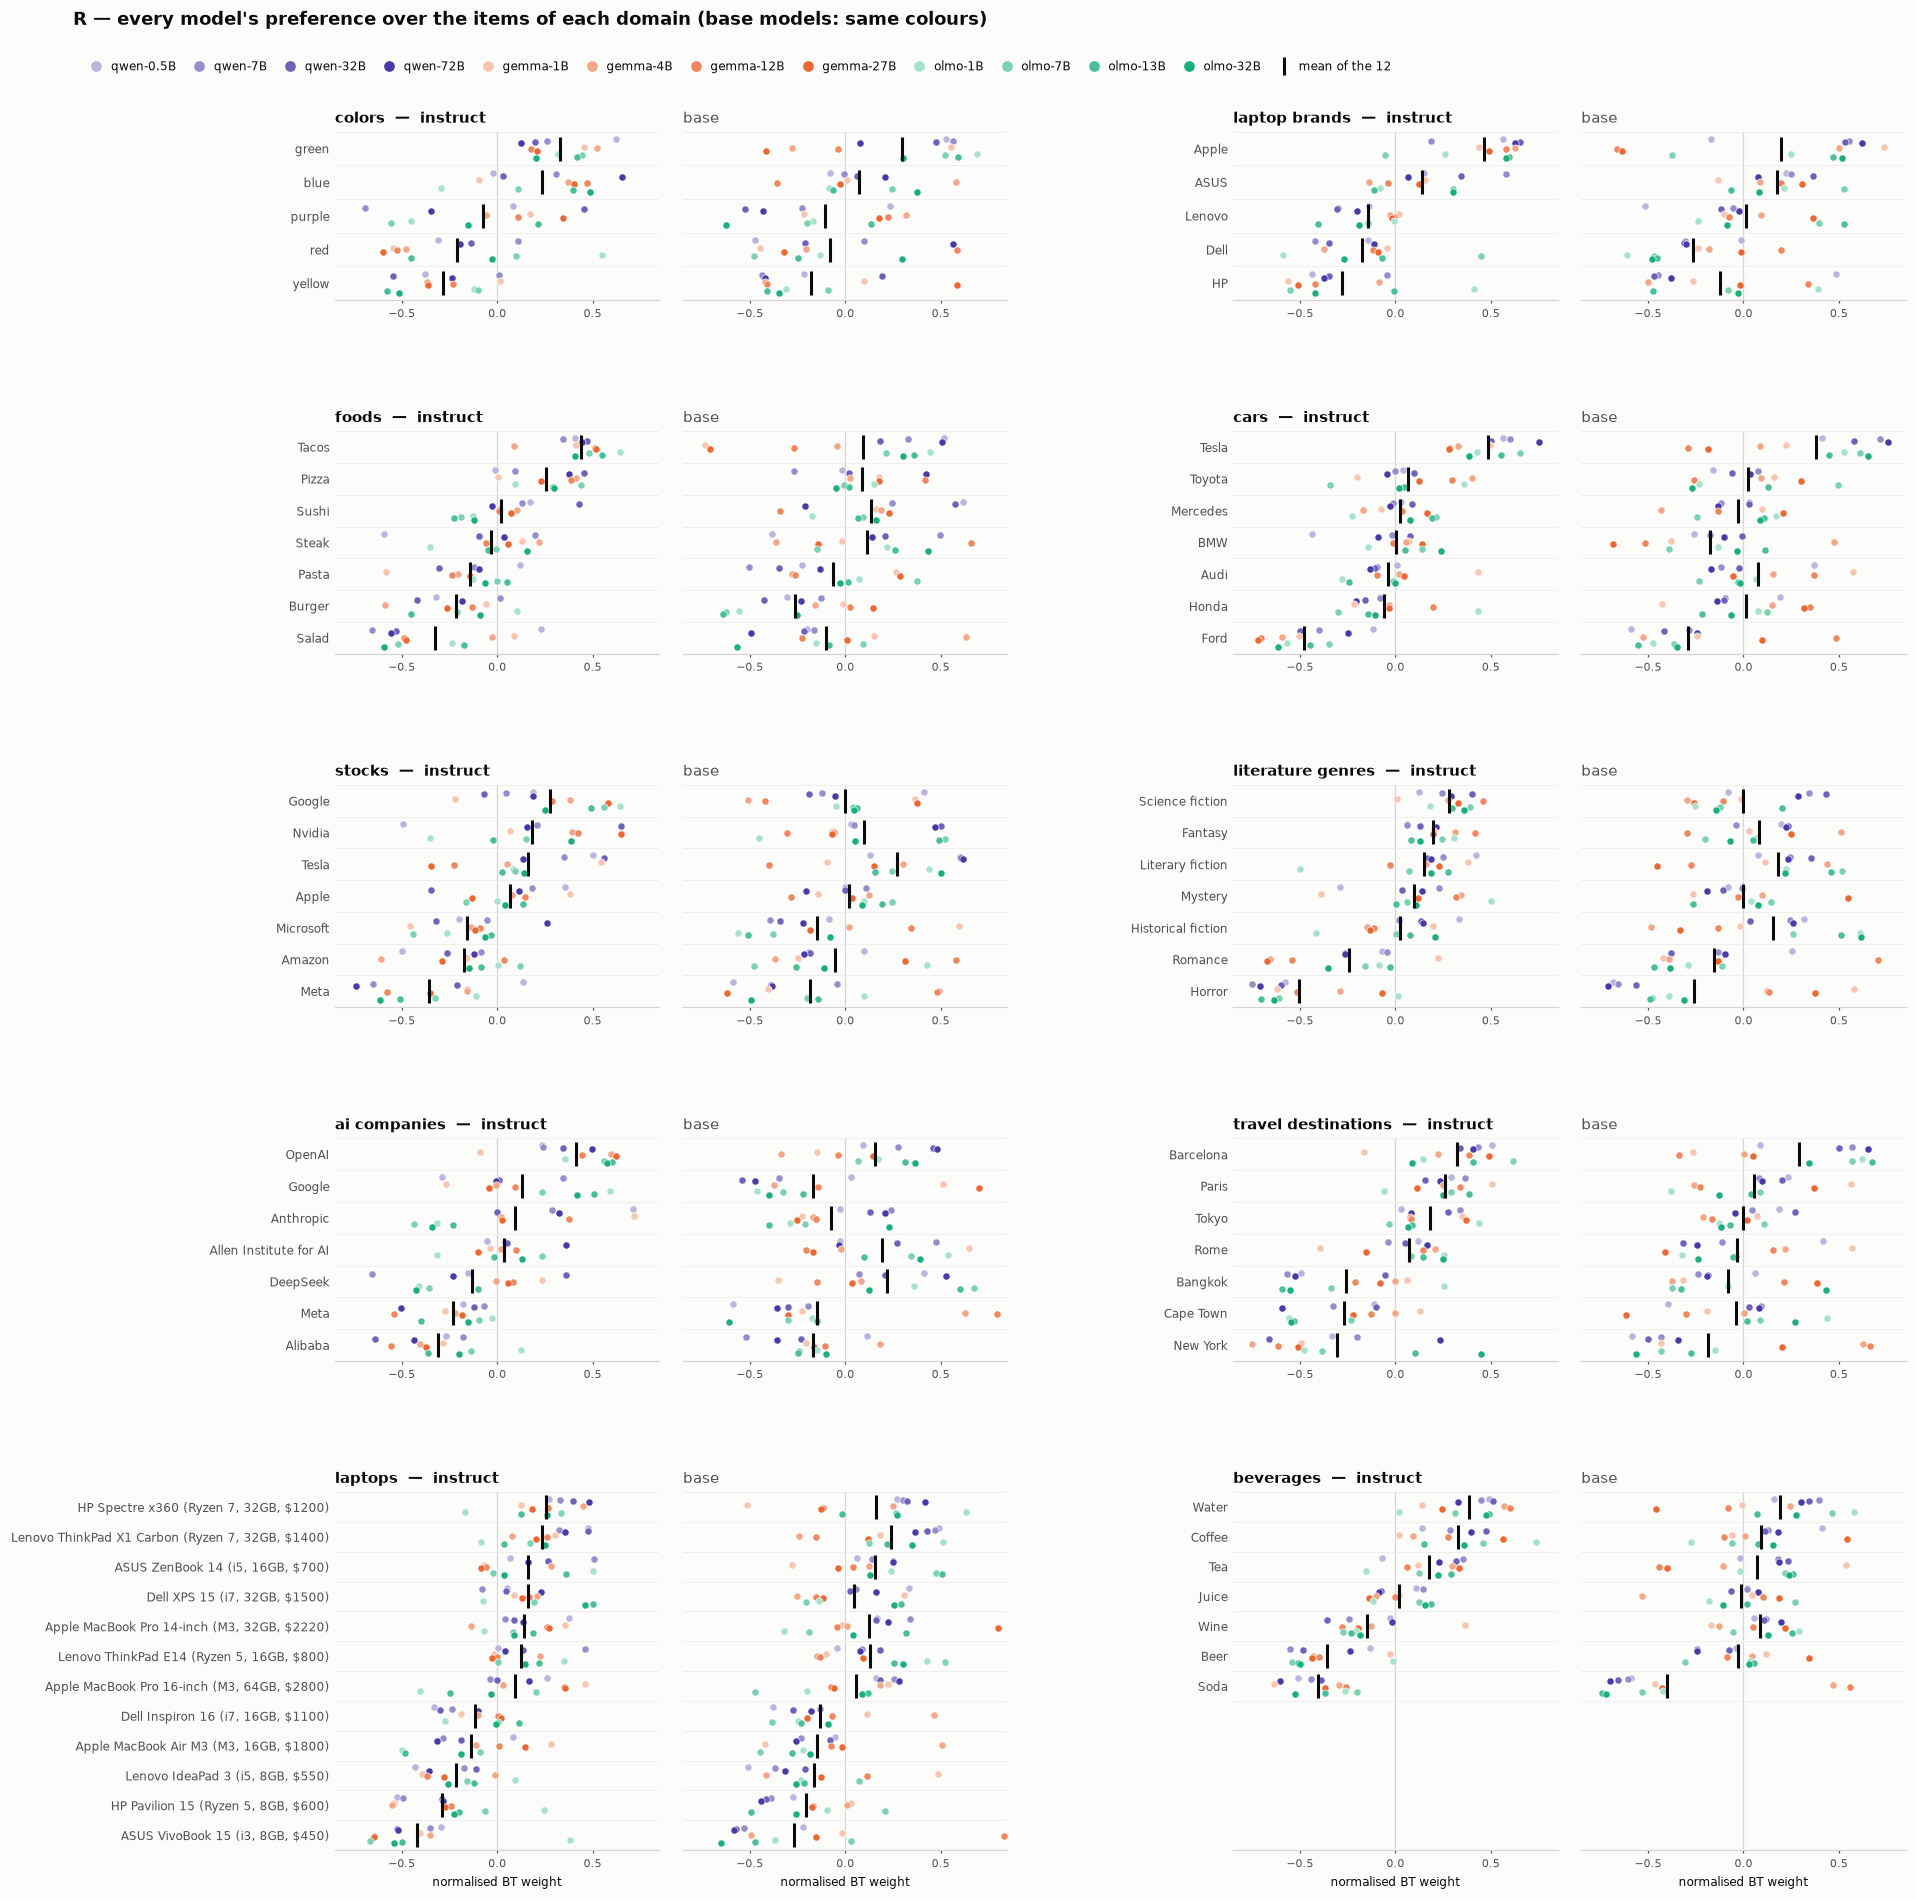

In [9]:
FAM_Y = {"qwen": -0.22, "gemma": 0.0, "olmo": 0.22}                 # vertical spread inside a row


def norm_bt(m, dom):
    b = BT[(*m, dom)]
    return b / (b.max() - b.min())


PAIRS = [("colors", "laptop_brands"), ("foods", "cars"), ("stocks", "literature_genres"),
         ("ai_companies", "travel_destinations"), ("laptops", "beverages")]
heights = [max(len(RUNS[(*MODELS[0], d)]["items"]) for d in pr) + 1.2 for pr in PAIRS]
fig = plt.figure(figsize=(17, 0.36 * sum(heights) + 1.5))
gs = fig.add_gridspec(len(PAIRS), 5, height_ratios=heights, width_ratios=[1, 1, 0.55, 1, 1], hspace=0.55, wspace=0.08,
                      left=0.15, right=0.99, top=1 - 1.2 / (0.36 * sum(heights) + 1.5), bottom=0.03)
for r, pr in enumerate(PAIRS):
    for c, dom in enumerate(pr):
        nI = {m: norm_bt(m, dom) for m in MODELS}
        order = pd.DataFrame({m: nI[m] for m in MODELS if not is_base(m)}).mean(axis=1).sort_values(ascending=False).index
        y0 = {it: i for i, it in enumerate(order)}
        axes = [fig.add_subplot(gs[r, 3 * c]), fig.add_subplot(gs[r, 3 * c + 1])]
        for ax, base in zip(axes, (False, True)):
            ms = [m for m in MODELS if is_base(m) == base]
            for m in ms:
                fam = m[0].replace("-pt", "")
                yy = [y0[it] + FAM_Y[fam] + (SIZES[fam].index(m[1]) - 1.5) * 0.04 for it in order]
                ax.scatter(nI[m][order].values, yy, s=22, color=model_color(m), edgecolor=SURFACE, lw=0.4, zorder=3)
            mean = pd.DataFrame({m: nI[m] for m in ms}).mean(axis=1)[order]
            ax.scatter(mean.values, np.arange(len(order)), marker="|", s=260, color=INK, lw=2, zorder=4)
            ax.axvline(0, color="#d6d5d1", lw=0.8, zorder=1)
            for k in range(len(order) + 1):
                ax.axhline(k - 0.5, color="#efeeeb", lw=0.6, zorder=1)
            ax.set_ylim(heights[r] - 1.7, -0.5)
            ax.set_xlim(-0.85, 0.85)
            ax.set_xticks([-0.5, 0, 0.5])
            ax.tick_params(labelsize=7.5, length=2)
            ax.spines["left"].set_visible(False)
            ax.set_title(("base" if base else f"{dom.replace('_', ' ')}  —  instruct"), loc="left",
                         fontsize=9.5, fontweight="normal" if base else "bold", color=INK_MUTED if base else INK)
            if base:
                ax.set_yticks([])
            else:
                ax.set_yticks(range(len(order)), order, fontsize=8)
            ax.tick_params(axis="y", length=0)
        if r == len(PAIRS) - 1:
            for ax in axes:
                ax.set_xlabel("normalised BT weight", fontsize=8)
hs = [plt.Line2D([], [], marker="o", ls="", color=model_color(m), ms=6, label=MNAME[m]) for m in MODELS[:12]]
hs.append(plt.Line2D([], [], marker="|", ls="", color=INK, ms=12, mew=2, label="mean of the 12"))
fig.legend(handles=hs, loc="upper left", ncol=13, frameon=False, fontsize=8, bbox_to_anchor=(0.01, 1 - 0.45 / fig.get_figheight()),
           columnspacing=0.9, handletextpad=0.2)
fig.suptitle("R — every model's preference over the items of each domain (base models: same colours)", x=0.01,
             y=1 - 0.1 / fig.get_figheight(), ha="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "R_all_domains.png"), facecolor=SURFACE)
plt.show()

## R1–R5 — how much do the models agree with each other?

Building block: for one domain, the **agreement of two models** = Spearman between their item orders
(Borda). +1 = the same order, 0 = unrelated, −1 = reversed. Domains have 5–12 items, so one domain's ρ is
noisy; most views average over the 10 domains (± SE over domains).

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

FAM = {m: m[0].replace("-pt", "") for m in MODELS}
TIER = {m: SIZES[FAM[m]].index(m[1]) for m in MODELS}             # 0..3 = smallest..largest of its family
IT = [m for m in MODELS if not is_base(m)]
PT = [m for m in MODELS if is_base(m)]
RHO = {}                                                          # RHO[dom] = 24 x 24 Spearman of the item orders
for dom in DOMAINS:
    V = pd.DataFrame({m: BORDA[(*m, dom)] for m in MODELS})
    RHO[dom] = V.corr(method="spearman")
RHO_MEAN = sum(RHO[d] for d in DOMAINS) / len(DOMAINS)

### R1 — agreement by kind of pair

Every pair of models falls in one kind: both instruct (**IT–IT**) or both base (**PT–PT**), from the **same
family** or **different** families; or an instruct model vs **its own base model** (same family and size),
or vs another base model. Bar = mean ρ over the pairs of that kind. Left: mean over domains ± SE. Right:
per domain, for the three main kinds.

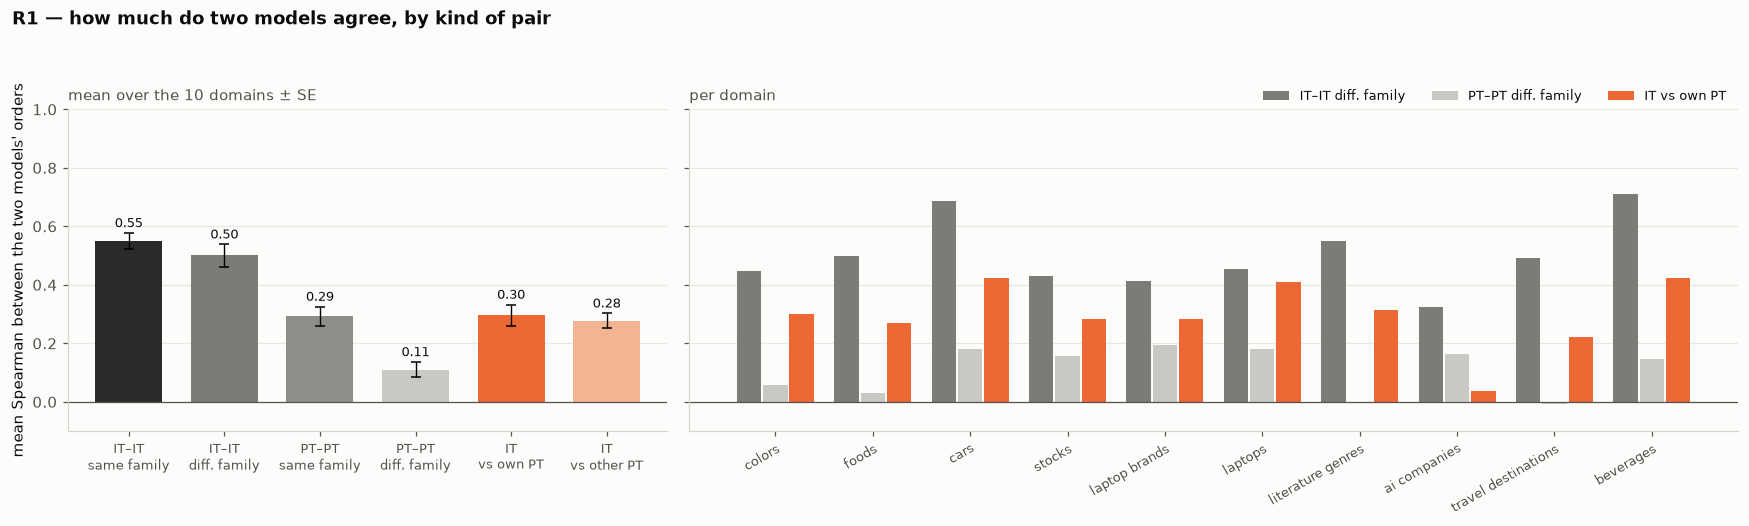

kind,IT–IT same family,IT–IT diff. family,PT–PT same family,PT–PT diff. family,IT vs own PT,IT vs other PT
domain,,,,,,
colors,0.52,0.45,0.17,0.06,0.30,0.27
foods,0.54,0.50,0.26,0.03,0.27,0.23
cars,0.65,0.69,0.35,0.18,0.42,0.37
stocks,0.43,0.43,0.26,0.16,0.28,0.27
laptop_brands,0.46,0.41,0.10,0.20,0.28,0.27
laptops,0.56,0.46,0.37,0.18,0.41,0.38
literature_genres,0.47,0.55,0.42,-0.00,0.32,0.24
ai_companies,0.62,0.32,0.31,0.16,0.04,0.16
travel_destinations,0.54,0.49,0.28,-0.01,0.22,0.20


In [11]:
def kind(a, b):
    if not is_base(a) and not is_base(b):
        return "IT–IT same family" if FAM[a] == FAM[b] else "IT–IT diff. family"
    if is_base(a) and is_base(b):
        return "PT–PT same family" if FAM[a] == FAM[b] else "PT–PT diff. family"
    return "IT vs own PT" if (FAM[a], a[1]) == (FAM[b], b[1]) else "IT vs other PT"


KINDS = ["IT–IT same family", "IT–IT diff. family", "PT–PT same family", "PT–PT diff. family", "IT vs own PT", "IT vs other PT"]
KCOL = {"IT–IT same family": "#2a2a28", "IT–IT diff. family": "#7d7b76", "PT–PT same family": "#8f8d87",
        "PT–PT diff. family": "#c9c8c3", "IT vs own PT": "#eb6834", "IT vs other PT": "#f3b493"}
pairs = [(a, b) for i, a in enumerate(MODELS) for b in MODELS[i + 1:]]
K = pd.DataFrame([{"domain": d, "kind": kind(a, b), "rho": RHO[d].loc[[a], [b]].values[0, 0]} for d in DOMAINS for a, b in pairs])
KD = K.groupby(["domain", "kind"]).rho.mean().unstack()[KINDS].loc[DOMAINS]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [0.8, 1.4]}, sharey=True)
mu, se = KD.mean(), KD.std(ddof=1) / np.sqrt(len(KD))
a1.bar(range(len(KINDS)), mu, 0.7, yerr=se, color=[KCOL[k] for k in KINDS], capsize=3, error_kw={"lw": 0.9}, zorder=2)
for i, k in enumerate(KINDS):
    a1.text(i, mu[k] + se[k] + 0.02, f"{mu[k]:.2f}", ha="center", fontsize=8.5)
a1.set_xticks(range(len(KINDS)), [k.replace(" ", "\n", 1) for k in KINDS], fontsize=8.5)
a1.set_title("mean over the 10 domains ± SE", loc="left", fontsize=9.5, color=INK_MUTED)
main = ["IT–IT diff. family", "PT–PT diff. family", "IT vs own PT"]
x = np.arange(len(DOMAINS))
for j, k in enumerate(main):
    a2.bar(x + (j - 1) * 0.27, KD[k], 0.25, color=KCOL[k], label=k, zorder=2)
a2.set_xticks(x, [d.replace("_", " ") for d in DOMAINS], rotation=30, ha="right", rotation_mode="anchor", fontsize=8.5)
a2.legend(frameon=False, fontsize=8.5, ncol=3, loc="upper right", bbox_to_anchor=(1, 1.1))
a2.set_title("per domain", loc="left", fontsize=9.5, color=INK_MUTED)
for ax in (a1, a2):
    ax.grid(True, axis="y", color="#e8e7e3")
    ax.axhline(0, color=INK_MUTED, lw=0.8)
a1.set_ylabel("mean Spearman between the two models' orders")
a1.set_ylim(-0.1, 1)
fig.suptitle("R1 — how much do two models agree, by kind of pair", x=0.01, y=1.03, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "R1_agreement_by_pair_kind.png"), facecolor=SURFACE)
plt.show()
KD.round(2)

### R2 — does a bigger model share the common taste more?

The **instruct consensus** of a domain = the mean normalised Borda score over the 12 instruct models (leave
the model itself out when it is one of them). y = Spearman between one model's order and the consensus,
mean over the 10 domains ± SE. x = size (log), one panel per family; solid = instruct, dashed = base.

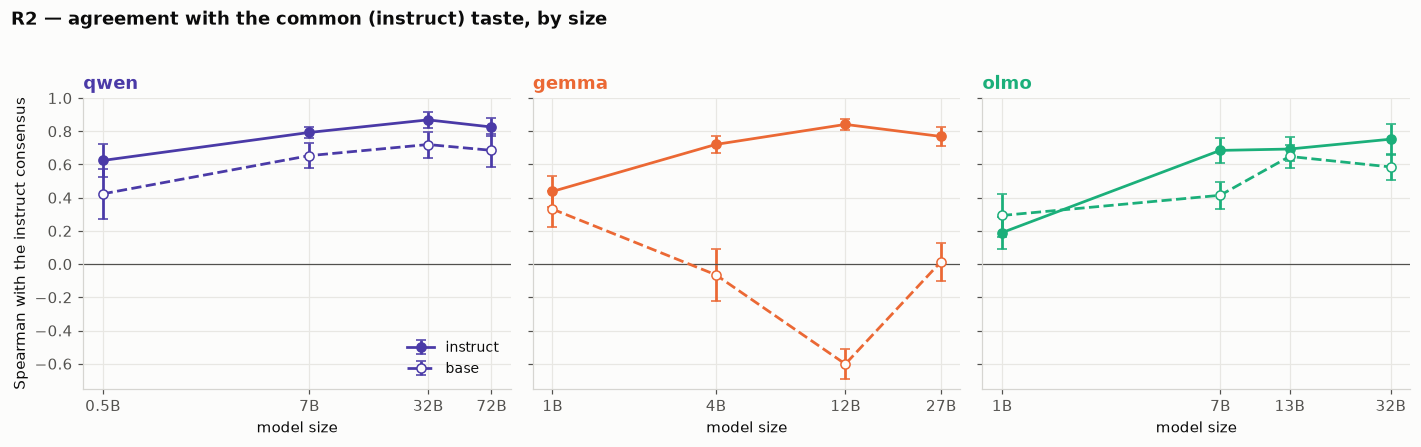

model,gemma-1B,gemma-12B,gemma-27B,gemma-4B,gemma-pt-1B,gemma-pt-12B,gemma-pt-27B,gemma-pt-4B,olmo-1B,olmo-13B,...,olmo-pt-32B,olmo-pt-7B,qwen-0.5B,qwen-32B,qwen-7B,qwen-72B,qwen-pt-0.5B,qwen-pt-32B,qwen-pt-7B,qwen-pt-72B
mean ρ with consensus,0.44,0.84,0.77,0.72,0.33,-0.6,0.01,-0.06,0.19,0.69,...,0.59,0.41,0.62,0.87,0.79,0.83,0.42,0.72,0.65,0.69


In [12]:
def nb_(m, dom):
    b = BORDA[(*m, dom)]
    return b / (b.max() - b.min())


cons_rows = []
for dom in DOMAINS:
    NB = pd.DataFrame({m: nb_(m, dom) for m in MODELS})
    for m in MODELS:
        others = [o for o in IT if o != m]
        cons_rows.append({"domain": dom, "model": m, "rho": spearmanr(NB[m], NB[others].mean(axis=1))[0]})
CONS = pd.DataFrame(cons_rows)
g = CONS.groupby("model").rho
CM, CS = g.mean(), g.std(ddof=1) / np.sqrt(len(DOMAINS))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for ax, fam in zip(axes, SIZES):
    sz = [float(s) for s in SIZES[fam]]
    for v, ls, lab in (("", "-", "instruct"), ("-pt", "--", "base")):
        ms = [(fam + v, s) for s in SIZES[fam]]
        ax.errorbar(sz, [CM[m] for m in ms], yerr=[CS[m] for m in ms], color=FAM_COL[fam], ls=ls, marker="o",
                    mfc=FAM_COL[fam] if v == "" else SURFACE, lw=1.8, capsize=3, label=lab)
    ax.set_xscale("log")
    ax.set_xticks(sz, [f"{s:g}B" for s in sz])
    ax.minorticks_off()
    ax.grid(True, color="#e8e7e3")
    ax.axhline(0, color=INK_MUTED, lw=0.8)
    ax.set_title(fam, loc="left", fontweight="bold", color=FAM_COL[fam])
    ax.set_xlabel("model size")
axes[0].set_ylabel("Spearman with the instruct consensus")
axes[0].set_ylim(-0.75, 1)
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("R2 — agreement with the common (instruct) taste, by size", x=0.01, y=1.03, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "R2_agreement_with_consensus.png"), facecolor=SURFACE)
plt.show()
CM.rename(index=MNAME).round(2).to_frame("mean ρ with consensus").T

### R3 — in which domains do the models agree?

**Kendall's W across models** (the same statistic as S1, but the "raters" are now the models, not the
templates): 1 = all models give the same order. Bars: the 12 instruct models, the 12 base models, and the
largest instruct model of each family (3). Dotted lines = what random orders would give (E[W] = 1 / number of models).

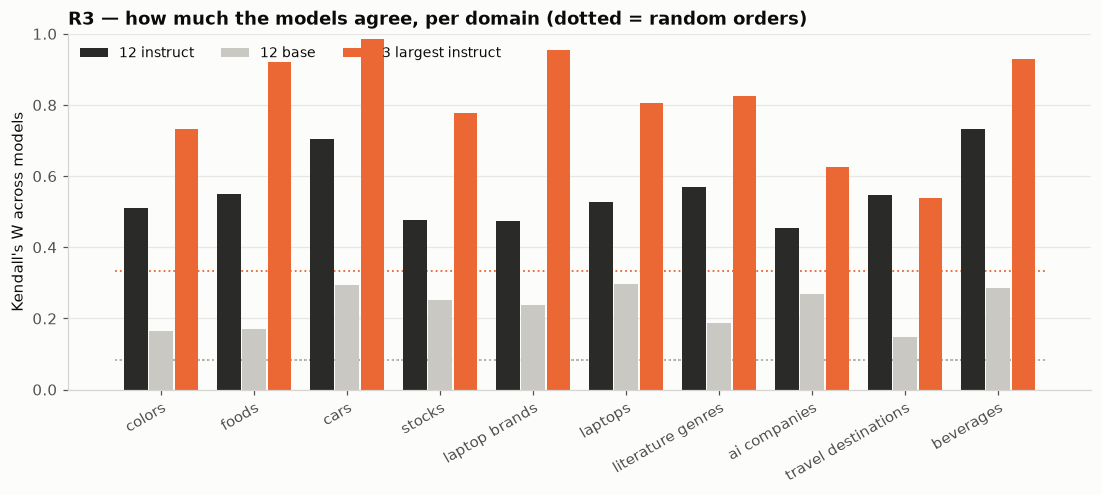

,colors,foods,cars,stocks,laptop_brands,laptops,literature_genres,ai_companies,travel_destinations,beverages
12 instruct,0.51,0.55,0.70,0.48,0.48,0.53,0.57,0.45,0.55,0.73
12 base,0.16,0.17,0.29,0.25,0.24,0.30,0.19,0.27,0.15,0.28
3 largest instruct,0.73,0.92,0.98,0.78,0.96,0.80,0.83,0.63,0.54,0.93


In [13]:
BIG = [m for m in IT if TIER[m] == 3]
GROUPS = [("12 instruct", IT, "#2a2a28"), ("12 base", PT, "#c9c8c3"), ("3 largest instruct", BIG, "#eb6834")]
W = pd.DataFrame({lab: {dom: kendall_w(np.array([rankdata(-BORDA[(*m, dom)][RUNS[(*m, dom)]["items"]]) for m in ms]))
                        for dom in DOMAINS} for lab, ms, _ in GROUPS}).loc[DOMAINS]
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(DOMAINS))
for j, (lab, ms, col) in enumerate(GROUPS):
    ax.bar(x + (j - 1) * 0.27, W[lab], 0.25, color=col, label=f"{lab}", zorder=2)
    ax.hlines(1 / len(ms), -0.5, len(DOMAINS) - 0.5, color=col, ls=":", lw=1.2, zorder=1)
ax.set_xticks(x, [d.replace("_", " ") for d in DOMAINS], rotation=30, ha="right", rotation_mode="anchor")
ax.set_ylabel("Kendall's W across models")
ax.set_ylim(0, 1)
ax.grid(True, axis="y", color="#e8e7e3")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper left")
ax.set_title("R3 — how much the models agree, per domain (dotted = random orders)", loc="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "R3_agreement_per_domain.png"), facecolor=SURFACE)
plt.show()
W.round(2).T

### R4 — which models think alike? (clustering)

Distance between two models = 1 − their mean ρ over the 10 domains; average-linkage clustering. Models
that join low down share the same tastes. If the tree splits first by family, family drives taste; if by
instruct / base, alignment does; if by size, scale does. Label colour = family, *(base)* = base model.

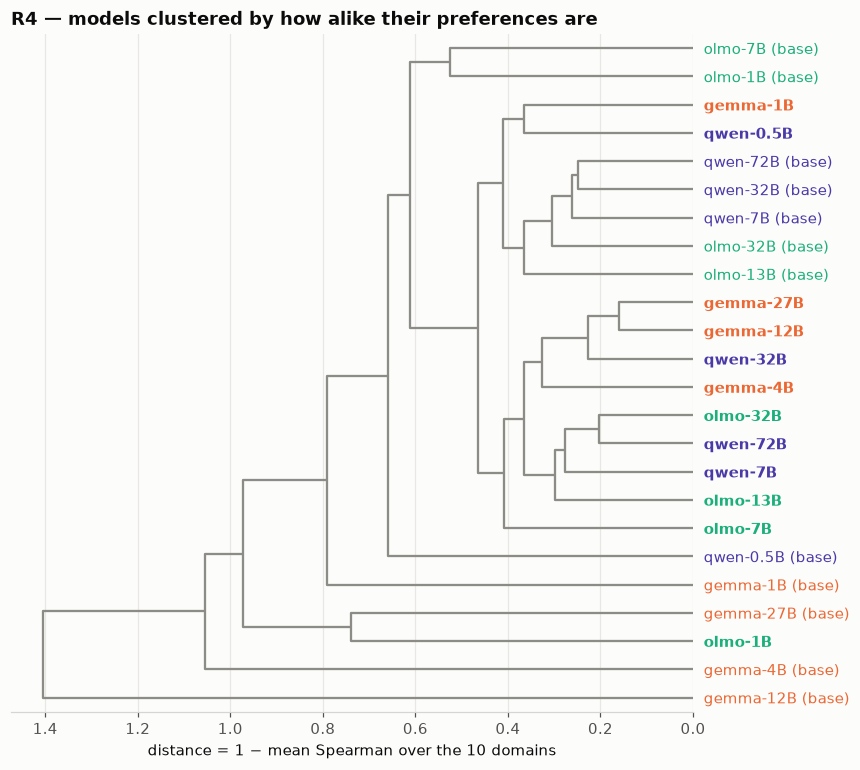

In [14]:
Dm = 1 - RHO_MEAN.values
np.fill_diagonal(Dm, 0)
Z = linkage(squareform(Dm, checks=False), method="average")
labels = [MNAME[m].replace("-pt", "") + (" (base)" if is_base(m) else "") for m in MODELS]
fig, ax = plt.subplots(figsize=(8, 8))
dn = dendrogram(Z, labels=labels, orientation="left", color_threshold=0, above_threshold_color="#8d8b85", ax=ax)
for t in ax.get_yticklabels():
    m = MODELS[labels.index(t.get_text())]
    t.set_color(FAM_COL[FAM[m]])
    t.set_fontweight("normal" if is_base(m) else "bold")
ax.set_xlabel("distance = 1 − mean Spearman over the 10 domains")
ax.grid(True, axis="x", color="#e8e7e3")
ax.spines["left"].set_visible(False)
ax.set_title("R4 — models clustered by how alike their preferences are", loc="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "R4_model_clusters.png"), facecolor=SURFACE)
plt.show()

### R5 — the taste of each family, aggregated over sizes

R again, but one dot per **family** (mean normalised BT weight over its 4 sizes): filled = instruct,
hollow = base. Whisker = the range over the 4 sizes (instruct only). Same item order as R. Where the three
filled dots sit together, the families share the taste; where the hollow dot sits far from its filled one,
instruct tuning changed it.

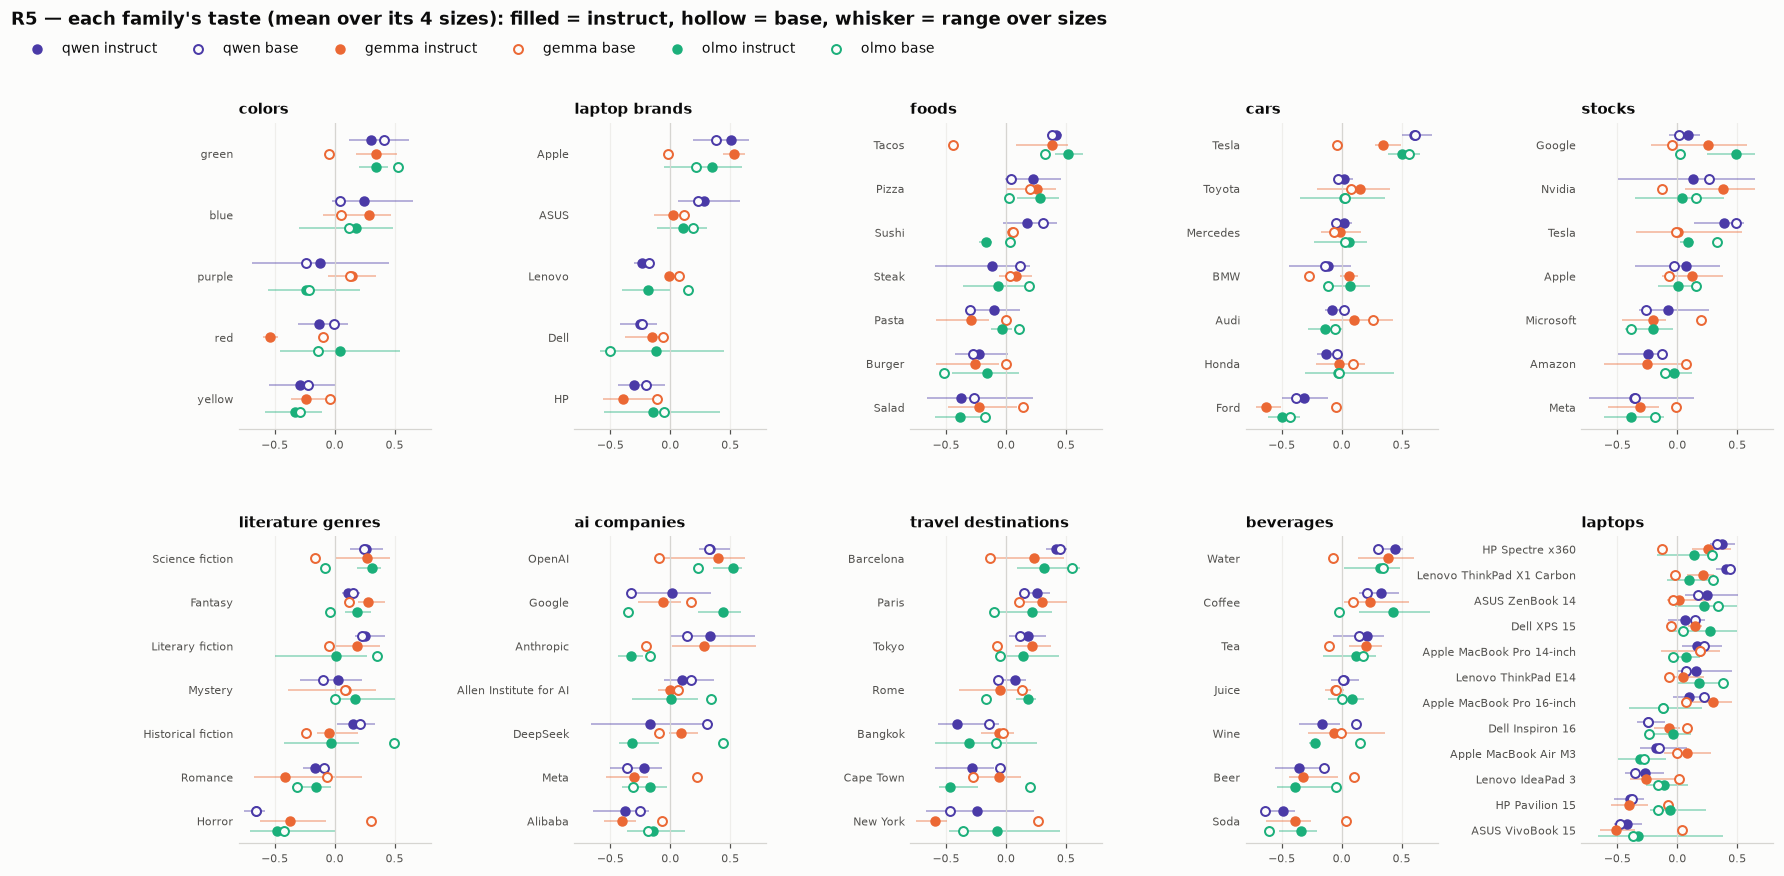

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8.5), gridspec_kw={"hspace": 0.35, "wspace": 0.75})
for ax, dom in zip(axes.flat, ["colors", "laptop_brands", "foods", "cars", "stocks",
                               "literature_genres", "ai_companies", "travel_destinations", "beverages", "laptops"]):
    nI = {m: norm_bt(m, dom) for m in MODELS}
    order = pd.DataFrame({m: nI[m] for m in IT}).mean(axis=1).sort_values(ascending=False).index
    for k, fam in enumerate(SIZES):
        off = (k - 1) * 0.22
        it = pd.DataFrame({m: nI[m] for m in IT if FAM[m] == fam}).loc[order]
        pt = pd.DataFrame({m: nI[m] for m in PT if FAM[m] == fam}).loc[order]
        y = np.arange(len(order)) + off
        ax.hlines(y, it.min(axis=1), it.max(axis=1), color=FAM_COL[fam], lw=1, alpha=0.5)
        ax.scatter(it.mean(axis=1), y, s=34, color=FAM_COL[fam], zorder=3, label=f"{fam} instruct")
        ax.scatter(pt.mean(axis=1), y, s=34, facecolor=SURFACE, edgecolor=FAM_COL[fam], lw=1.3, zorder=3, label=f"{fam} base")
    ax.axvline(0, color="#d6d5d1", lw=0.8)
    ax.set_yticks(range(len(order)), [o if len(o) < 22 else o.split(" (")[0] for o in order], fontsize=7.5)
    ax.set_ylim(len(order) - 0.5, -0.5)
    ax.set_xlim(-0.8, 0.8)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.grid(True, axis="x", color="#efeeeb")
    ax.spines["left"].set_visible(False)
    ax.set_title(dom.replace("_", " "), loc="left", fontweight="bold", fontsize=10)
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper left", ncol=6, frameon=False, fontsize=9, bbox_to_anchor=(0.01, 0.98))
fig.suptitle("R5 — each family's taste (mean over its 4 sizes): filled = instruct, hollow = base, whisker = range over sizes",
             x=0.01, y=1.0, ha="left", fontweight="bold")
fig.savefig(os.path.join(FIGDIR, "R5_family_taste.png"), facecolor=SURFACE)
plt.show()

## A — does each model prefer its own maker?

qwen = Alibaba, gemma = Google, olmo = Allen Institute for AI. Rank of the maker among the 7 companies
(1 = top), and the model's top pick.

In [16]:
MAKER = {"qwen": "Alibaba", "gemma": "Google", "olmo": "Allen Institute for AI"}
own = []
for m in MODELS:
    b = BORDA[(*m, "ai_companies")]
    fam = m[0].replace("-pt", "")
    own.append({"model": MNAME[m].replace("-pt", ""), "variant": "base" if m[0].endswith("-pt") else "instruct",
                "maker": MAKER[fam], "maker rank (of 7)": int(b.rank(ascending=False)[MAKER[fam]]),
                "top pick": b.index[0]})
OWN = pd.DataFrame(own)
OWN.to_csv(os.path.join(FIGDIR, "A_own_maker.csv"), index=False)
OWN.pivot(index="model", columns="variant", values="maker rank (of 7)").loc[[MNAME[m] for m in MODELS[:12]]] \
   .join(OWN[OWN.variant == "instruct"].set_index("model")["top pick"].rename("top pick (instruct)"))

,base,instruct,top pick (instruct)
model,,,
qwen-0.5B,2,6,Anthropic
qwen-7B,7,6,Google
qwen-32B,5,7,DeepSeek
qwen-72B,5,7,OpenAI
gemma-1B,2,7,Anthropic
gemma-4B,7,4,OpenAI
gemma-12B,7,3,OpenAI
gemma-27B,1,4,OpenAI
olmo-1B,1,5,Google


## B — bug check: the 6 old domains against the old runs

The old domains were re-run to check the old results. Old runs: `eos_fix_qwen` (qwen instruct, May 2026, the
same 43 templates) and `qwen_pt` (qwen base, June 2026, the 43 instruct templates — the new base runs use the
25 `pretrained` ones, so only the order can be compared there).

- **raw r** — Pearson of `m` on the same (pair, template) rows, old vs new (instruct only). Near 1 = the same
  numbers came out, so nothing broke.
- **order ρ** — Spearman of the Borda orders, old vs new.

In [17]:
def load_old(folder, fam, size, dom):
    for r in sorted(os.listdir(folder)):
        cf, sc = f"{folder}/{r}/config.json", f"{folder}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        if (c["model_family"], str(c["model_size"]), c["alternatives"]) == (fam, size, dom):
            return pd.read_csv(sc).rename(columns={"option_a": "a_item", "option_b": "b_item"})
    return None


bug = []
for folder, fam in (("data/eos_fix_qwen", "qwen"), ("data/qwen_pt", "qwen-pt")):
    for size in SIZES["qwen"]:
        for dom in DOMAINS[:6]:
            old = load_old(folder, fam, size, dom)
            if old is None:
                continue
            items = RUNS[(fam, size, dom)]["items"]
            Mo = tensor(old, items)
            n = len(items); off = ~np.eye(n, dtype=bool)
            Do = (Mo - Mo.transpose(0, 2, 1)) / 2
            bo = pd.Series(np.array([Do[t][off].reshape(n, n - 1).mean(1) for t in range(len(Do))]).mean(0), index=items)
            row = {"model": MNAME[(fam, size)], "domain": dom, "old folder": folder.split("/")[1],
                   "order ρ": spearmanr(bo[items], BORDA[(fam, size, dom)][items])[0], "raw r": np.nan}
            if fam == "qwen":
                Mn = RUNS[(fam, size, dom)]["M"]
                row["raw r"] = np.corrcoef(Mo[:, off].ravel(), Mn[:, off].ravel())[0, 1]
            bug.append(row)
BUG = pd.DataFrame(bug)
BUG.to_csv(os.path.join(FIGDIR, "B_old_vs_new.csv"), index=False)
ORDER = [MNAME[m] for m in MODELS if m[0] in ("qwen", "qwen-pt")]
print(BUG[BUG["old folder"] == "eos_fix_qwen"].pivot(index="model", columns="domain", values="raw r").loc[ORDER[:4], DOMAINS[:6]].round(3).to_string(), "\n")
print(BUG.pivot(index="model", columns="domain", values="order ρ").loc[ORDER, DOMAINS[:6]].round(2).to_string())

domain     colors  foods   cars  stocks  laptop_brands  laptops
model                                                          
qwen-0.5B   0.996  0.995  0.996   0.996          0.996    0.996
qwen-7B     0.999  0.999  1.000   0.999          0.998    0.999
qwen-32B    0.999  1.000  1.000   0.999          1.000    0.999
qwen-72B    0.999  1.000  1.000   1.000          1.000    1.000 

domain        colors  foods  cars  stocks  laptop_brands  laptops
model                                                            
qwen-0.5B        1.0   1.00  0.96    0.96            1.0     1.00
qwen-7B          1.0   1.00  1.00    1.00            1.0     1.00
qwen-32B         1.0   1.00  1.00    0.96            1.0     1.00
qwen-72B         1.0   1.00  1.00    0.96            1.0     1.00
qwen-pt-0.5B     0.9  -0.04  0.57    0.21            0.1     0.54
qwen-pt-7B       0.5   0.86  0.82    0.43            0.1     0.90
qwen-pt-32B      0.3   0.61  0.61    0.79            0.9     0.71
qwen-pt-72B      0.9

## E — domain summary: coherence, sharpness, agreement

Per domain, three bars, all on 0–1:
- **coherence** — Spearman between the BT order and the Borda order (do the pairwise choices settle into one order?);
- **sharpness** — how certain the choices are: `|2P_t − 1|` with `P_t(x over y) = ½ [σ(m_t(x,y)) + 1 − σ(m_t(y,x))]`
  (the chance the user gets x when the pair is shown in random order, per template; PMI is off here).
  **A1** = mean over all pairs and templates; **A2** = only each item vs the next one in the BT order;
- **agreement** — Kendall's W across the models of the regime (one number per domain).

Coherence and sharpness = mean over the models of the regime. Left panel: the tuned (instruct) models, sharpness
= A1. Right panel: the three measures averaged over the domains shown, base (hatched) vs tuned (solid); error
bar = SE over those domains. Six domains shown: the two laptop domains are left out (the laptops have their own figures), and foods and
stocks too (in the middle on every measure; stocks also mixes taste with knowledge of company value).

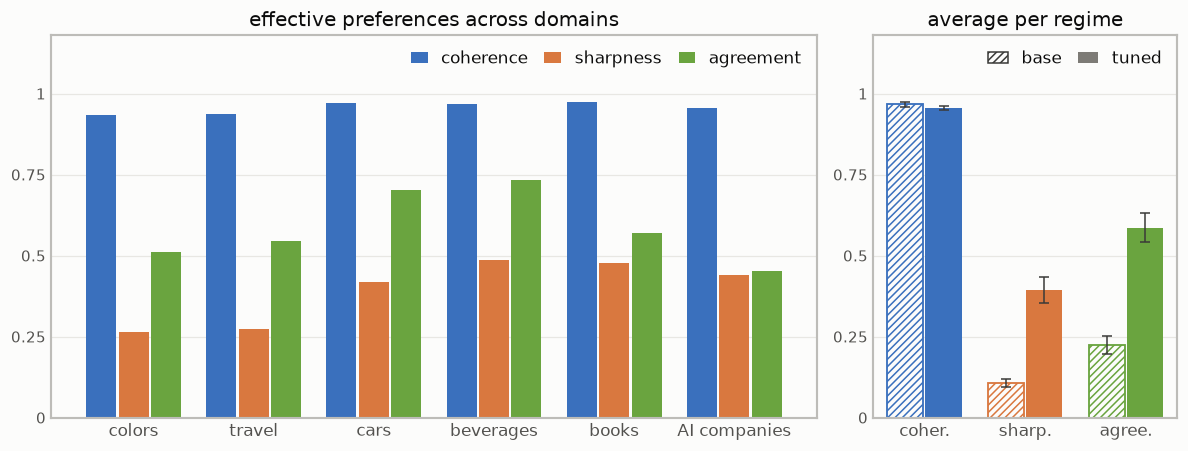

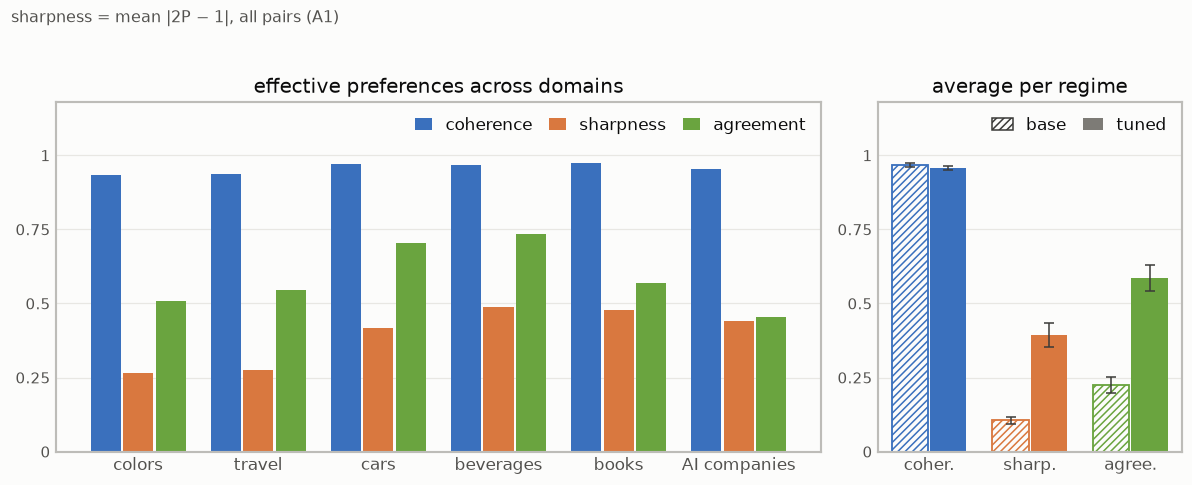

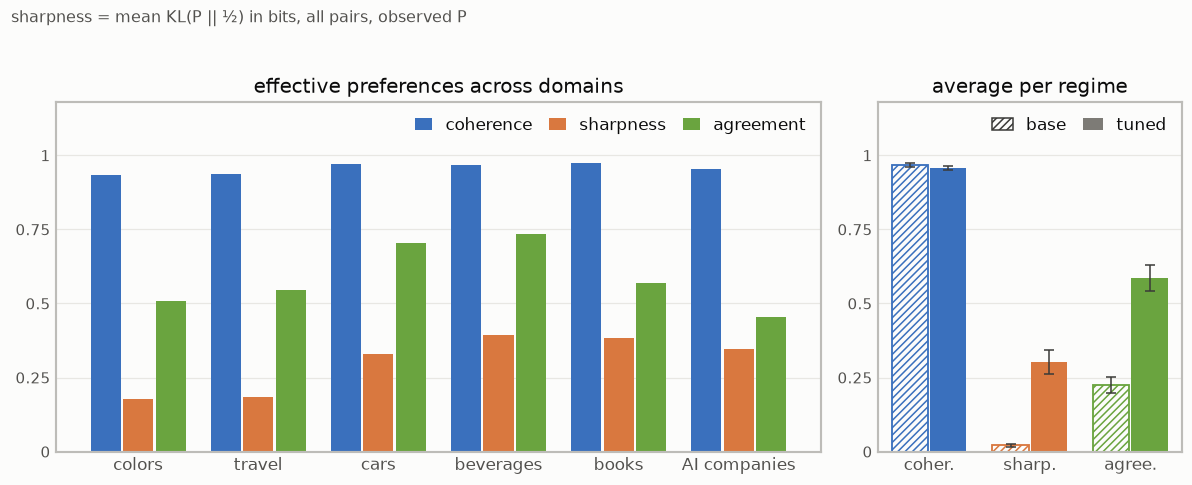

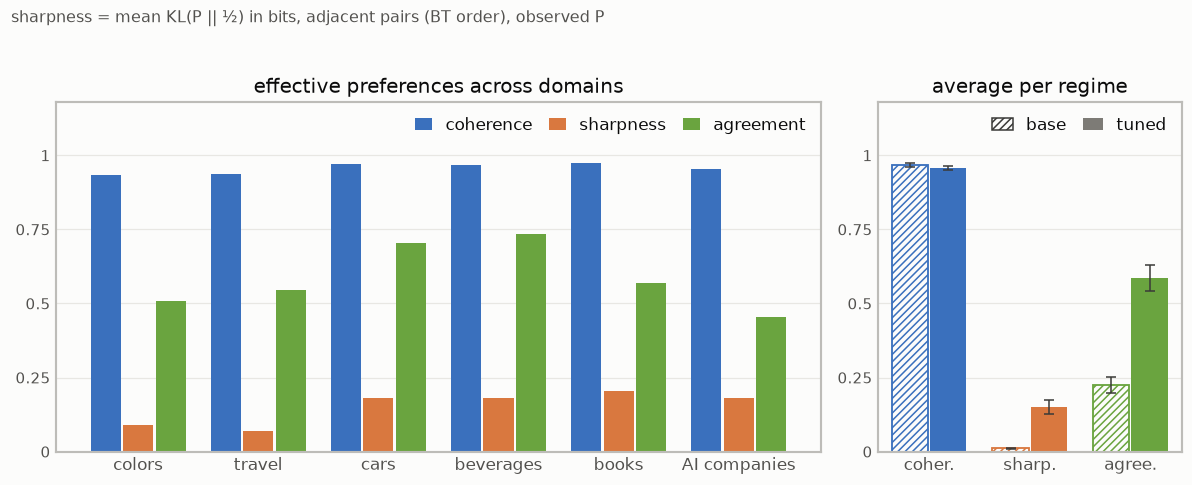

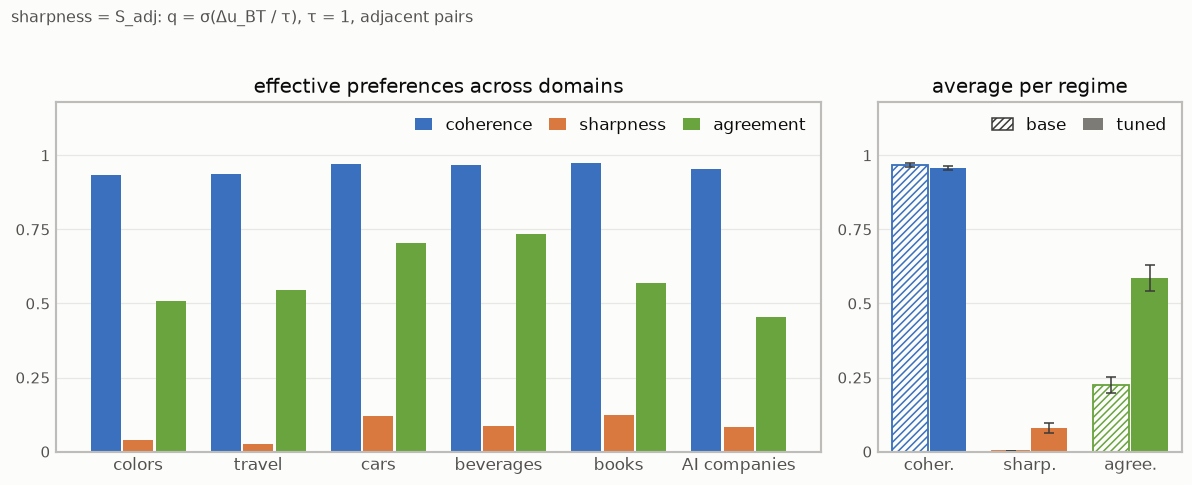

In [18]:
def sig(x):
    return 1 / (1 + np.exp(-x))


def h2(p):
    """Binary entropy in bits; 1 - h2(p) = KL(Bern(p) || Bern(1/2)) in bits."""
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


def sharpness(M, bt, tau=1.0):
    """Sharpness candidates for one run. M[t, i, j] = margin, items in RUNS order; bt indexed the same."""
    P = 0.5 * (sig(M) + 1 - sig(M.transpose(0, 2, 1)))
    cert, info = np.abs(2 * P - 1), 1 - h2(P)
    iu = np.triu_indices(M.shape[1], 1)
    order = np.argsort(-bt.values)                                  # most liked first, by BT
    adj = list(zip(order[:-1], order[1:]))
    q = np.array([sig((bt.values[a] - bt.values[b]) / tau) for a, b in adj])
    return {"A1": cert[:, iu[0], iu[1]].mean(),
            "A2": np.mean([cert[:, a, b].mean() for a, b in adj]),
            "KL-all": info[:, iu[0], iu[1]].mean(),
            "KL-adj": np.mean([info[:, a, b].mean() for a, b in adj]),
            "S_adj": np.mean(1 - h2(q)),
            # position-free: average the two orders in log-odds (D), then certainty |2 sigma(D) - 1| = tanh(|D| / 2)
            "intrinsic": np.tanh(np.abs((M - M.transpose(0, 2, 1))[:, iu[0], iu[1]] / 2) / 2).mean()}


rows = []
for (fam, size, dom), R in RUNS.items():
    b, bt = BORDA[(fam, size, dom)][R["items"]], BT[(fam, size, dom)][R["items"]]
    rows.append({"model": (fam, size), "regime": "base" if fam.endswith("-pt") else "tuned", "domain": dom,
                 "coherence": spearmanr(bt, b)[0], **sharpness(R["M"], bt)})
SH = pd.DataFrame(rows)

REGIMES = {"tuned": IT, "base": PT, "all": IT + PT}
DOMV = {}                                                           # regime -> per-domain table
for reg, ms in REGIMES.items():
    sub = SH if reg == "all" else SH[SH.regime == reg]
    T = sub.groupby("domain")[["coherence", "A1", "A2", "KL-all", "KL-adj", "S_adj", "intrinsic"]].mean().loc[DOMAINS]
    T["agreement"] = [kendall_w(np.array([rankdata(-BORDA[(*m, d)][RUNS[(*m, d)]["items"]]) for m in ms])) for d in DOMAINS]
    DOMV[reg] = T
pd.concat(DOMV, names=["regime"]).round(3).to_csv(os.path.join(FIGDIR, "E_domain_summary.csv"))

MCOL = {"coherence": "#3a70bd", "sharpness": "#d9783f", "agreement": "#6aa43f"}
DOMS_E = ["colors", "travel_destinations", "cars", "beverages", "literature_genres", "ai_companies"]
DLABEL = {"literature_genres": "books", "ai_companies": "AI companies", "travel_destinations": "travel"}
YTOP = 1.18                                                         # room above 1 for the legends


def frame(ax):
    ax.set_ylim(0, YTOP)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0", "0.25", "0.5", "0.75", "1"])
    ax.grid(True, axis="y", color="#e8e7e3", lw=0.8, zorder=0)
    ax.tick_params(length=0, labelsize=10)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#bdbcb8"); sp.set_linewidth(1.4)


def fig_e(left="tuned", cand="A1", doms=DOMS_E, fname="E_domain_summary", tag=None):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(4 + 1.15 * len(doms), 4.2),
                                 gridspec_kw={"width_ratios": [0.42 * len(doms), 1]})
    cols = {"coherence": "coherence", "sharpness": cand, "agreement": "agreement"}
    x = np.arange(len(doms))
    T = DOMV[left].loc[doms]
    for j, (lab, col) in enumerate(cols.items()):
        a1.bar(x + (j - 1) * 0.27, T[col].clip(lower=0), 0.25, color=MCOL[lab], label=lab, zorder=2)
    frame(a1)
    a1.set_xticks(x, [DLABEL.get(d, d.replace("_", " ")) for d in doms], fontsize=11)
    a1.legend(frameon=False, ncol=3, loc="upper right", fontsize=11, handlelength=1, columnspacing=1)
    a1.set_title("effective preferences across domains", fontsize=13)

    for i, (lab, col) in enumerate(cols.items()):
        for j, reg in enumerate(("base", "tuned")):
            v = DOMV[reg].loc[doms, col]
            a2.bar(i + (j - 0.5) * 0.38, v.mean(), 0.36, yerr=v.std(ddof=1) / np.sqrt(len(v)), capsize=3,
                   error_kw={"lw": 1, "ecolor": "#3a3a38"}, zorder=2,
                   color=SURFACE if reg == "base" else MCOL[lab], edgecolor=MCOL[lab],
                   hatch="/////" if reg == "base" else None, lw=1.2 if reg == "base" else 0)
    frame(a2)
    a2.set_xticks(range(3), ["coher.", "sharp.", "agree."], fontsize=11)
    a2.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor="#3a3a38", hatch="/////", label="base"),
                       plt.Rectangle((0, 0), 1, 1, facecolor="#7d7b76", label="tuned")],
              frameon=False, fontsize=11, loc="upper right", ncol=2, handlelength=1.2, columnspacing=1)
    a2.set_title("average per regime", fontsize=13)
    if tag:
        fig.suptitle(tag, x=0.01, y=1.04, ha="left", fontsize=10.5, color=INK_MUTED)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE)
    fig.savefig(os.path.join(FIGDIR, fname + ".pdf"), facecolor=SURFACE)
    plt.show()


fig_e()


# empirical choice of the sharpness formula: the same figure with each candidate
CAND_TAG = {"A1": "sharpness = mean |2P − 1|, all pairs (A1)",
            "KL-all": "sharpness = mean KL(P || ½) in bits, all pairs, observed P",
            "KL-adj": "sharpness = mean KL(P || ½) in bits, adjacent pairs (BT order), observed P",
            "S_adj": "sharpness = S_adj: q = σ(Δu_BT / τ), τ = 1, adjacent pairs"}
for cand, tag in CAND_TAG.items():
    fig_e(cand=cand, fname=f"E_candidate_{cand}", tag=tag)


## F — looking at sharpness from other angles

Same per-run numbers as E (one value per model × domain), on the 6 domains of the summary figure. Every view is
drawn for **A1** (mean |2P − 1|) and **KL-all** (mean KL(P ‖ ½) in bits, all pairs).

- **F1** — the spread over models, per domain: box with every model as a dot, tuned vs base (no violin: 12
  points are too few to estimate a distribution).
- **F2** — sharpness per **model** (mean over the 6 domains ± SE), instead of per domain.
- **F4** — boxes by **model size**: one panel per family, x = size, the box spreads over the 6 domains.

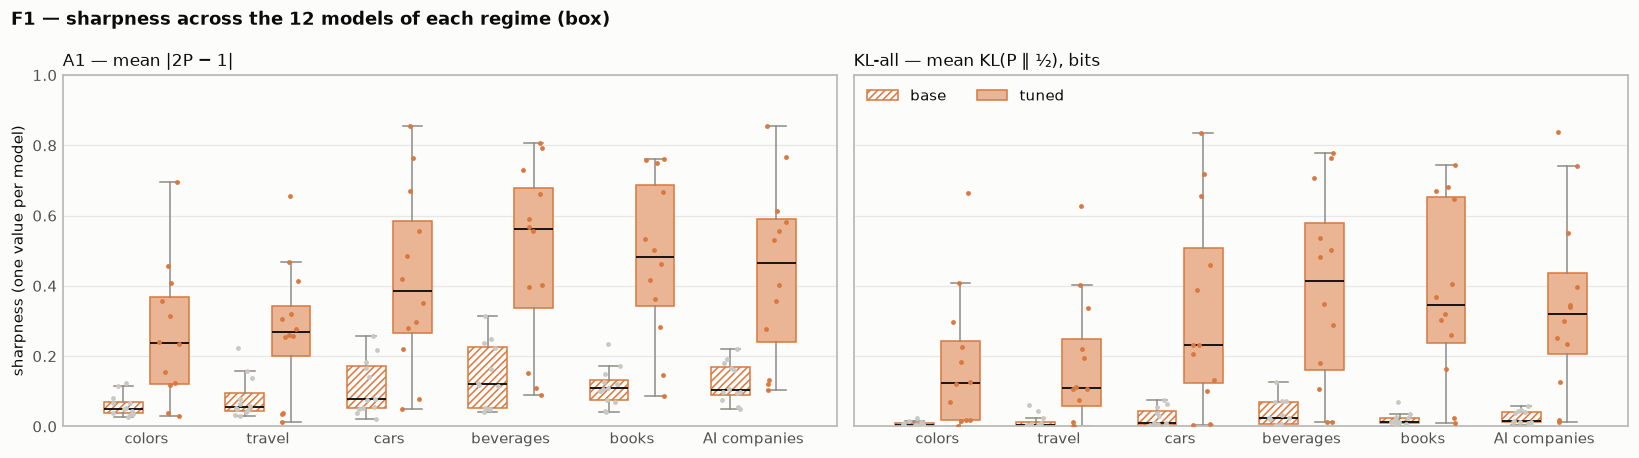

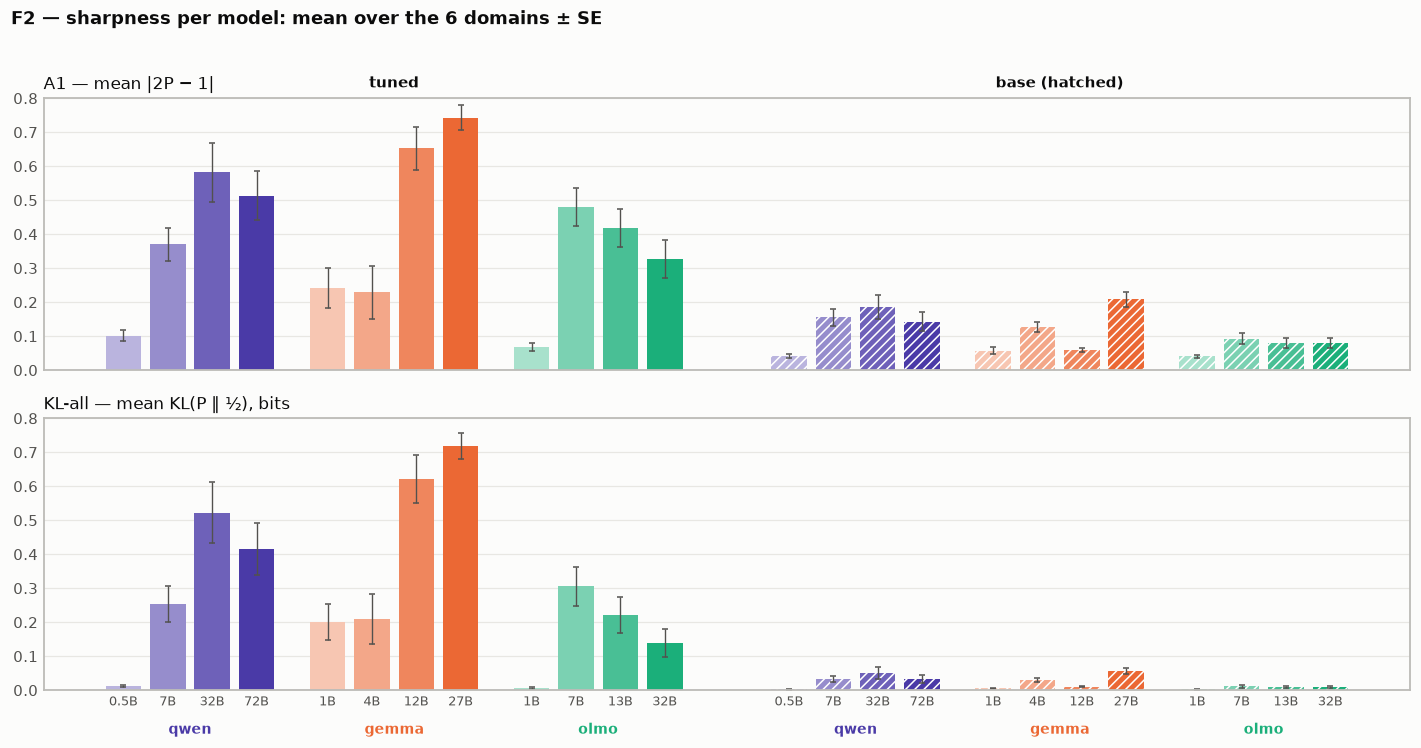

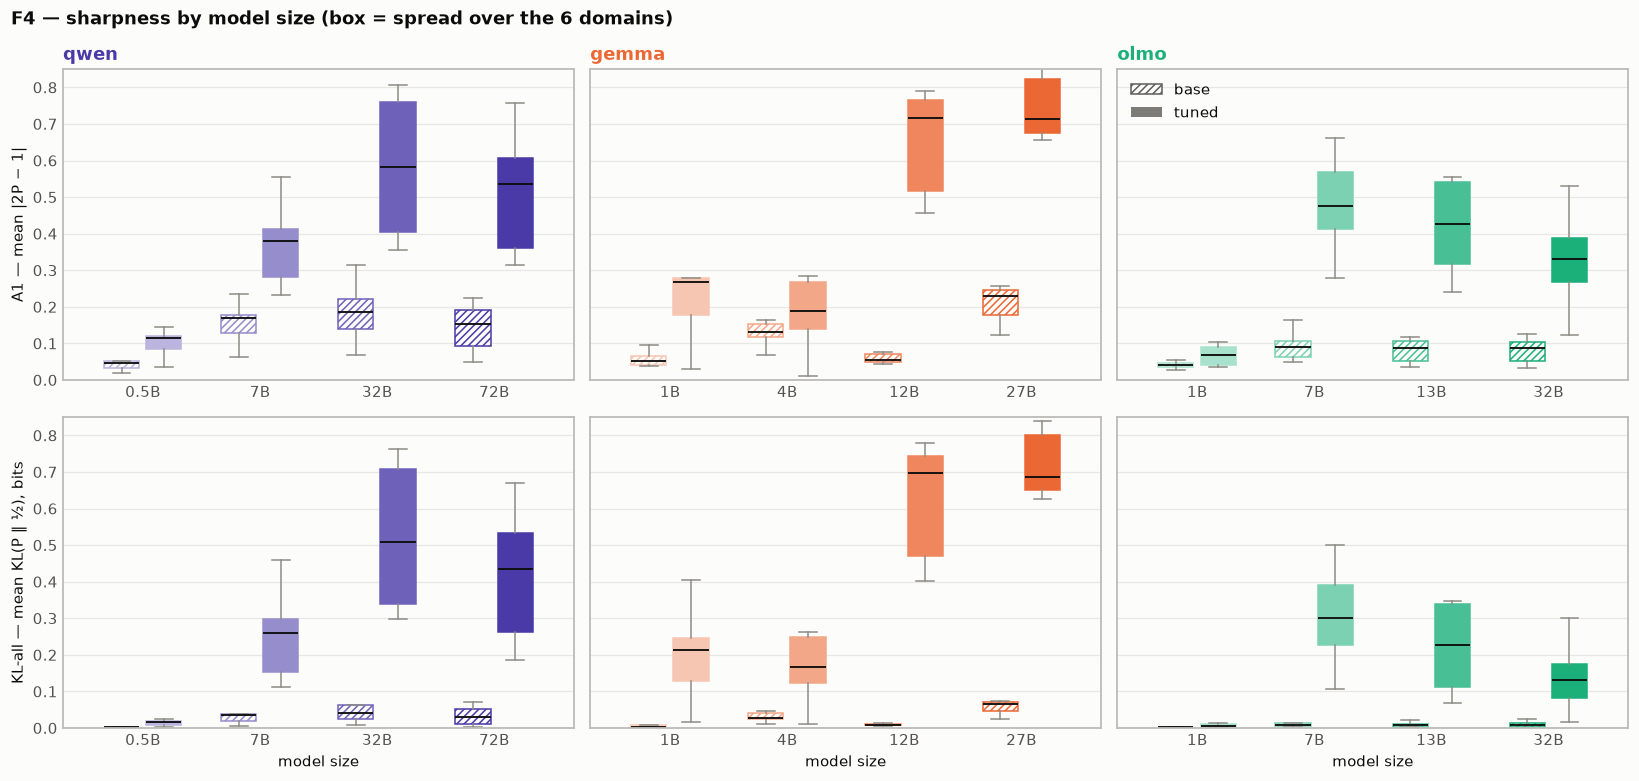

In [19]:
FAM_MK = {"qwen": "o", "gemma": "s", "olmo": "D"}



CANDS = {"A1": "A1 — mean |2P − 1|", "KL-all": "KL-all — mean KL(P ‖ ½), bits"}
SHF = SH[SH.domain.isin(DOMS_E)].copy()
SHF["family"] = SHF.model.map(lambda m: m[0].replace("-pt", ""))
SHF["size"] = SHF.model.map(lambda m: float(m[1]))
SHF["dlabel"] = SHF.domain.map(lambda d: DLABEL.get(d, d.replace("_", " ")))
DL = [DLABEL.get(d, d.replace("_", " ")) for d in DOMS_E]


def box_frame(ax, top=1.0):
    ax.set_ylim(0, top)
    ax.grid(True, axis="y", color="#e8e7e3", lw=0.8, zorder=0)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#bdbcb8"); sp.set_linewidth(1.2)
    ax.tick_params(length=0)


# ---- F1: spread over the models, per domain (box with dots, and violin) ----
for kind in ("box",):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
    for ax, (cand, title) in zip(axes, CANDS.items()):
        for i, d in enumerate(DOMS_E):
            for j, reg in enumerate(("base", "tuned")):
                v = SHF[(SHF.domain == d) & (SHF.regime == reg)][cand].values
                x = i + (j - 0.5) * 0.38
                col = "#d9783f"
                if kind == "box":
                    b = ax.boxplot(v, positions=[x], widths=0.32, patch_artist=True, showfliers=False,
                                   medianprops={"color": INK, "lw": 1.2}, whiskerprops={"color": "#8d8b85"},
                                   capprops={"color": "#8d8b85"})
                    b["boxes"][0].set(facecolor=SURFACE if reg == "base" else pale(col, 0.45), edgecolor=col,
                                      hatch="/////" if reg == "base" else None)
                    ax.scatter(x + np.random.default_rng(i * 2 + j).uniform(-0.09, 0.09, len(v)), v, s=10,
                               color=col if reg == "tuned" else "#c9c8c3", zorder=3, lw=0)
                else:
                    vp = ax.violinplot(v, positions=[x], widths=0.34, showmedians=True, showextrema=False)
                    for body in vp["bodies"]:
                        body.set(facecolor=SURFACE if reg == "base" else pale(col, 0.4), edgecolor=col, alpha=1,
                                 hatch="/////" if reg == "base" else None)
                    vp["cmedians"].set(color=INK, lw=1.2)
        ax.set_xticks(range(len(DOMS_E)), DL)
        ax.set_title(title, loc="left", fontsize=11)
        box_frame(ax)
    axes[0].set_ylabel("sharpness (one value per model)")
    axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor="#d9783f", hatch="/////", label="base"),
                            plt.Rectangle((0, 0), 1, 1, facecolor=pale("#d9783f", 0.45), edgecolor="#d9783f", label="tuned")],
                   frameon=False, loc="upper left", ncol=2)
    fig.suptitle(f"F1 — sharpness across the 12 models of each regime ({kind})", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"F1_sharpness_spread_{kind}.png"), facecolor=SURFACE)
    plt.show()


# ---- F2: sharpness per model (mean over the 6 domains +- SE) ----
fig, axes = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True)
xs = [i + (i // 4) * 0.6 + (1.2 if i >= 12 else 0) for i in range(len(MODELS))]
for ax, (cand, title) in zip(axes, CANDS.items()):
    for x, m in zip(xs, MODELS):
        v = SHF[SHF.model == m][cand]
        ax.bar(x, v.mean(), 0.8, yerr=v.std(ddof=1) / np.sqrt(len(v)), color=model_color(m), capsize=2,
               error_kw={"lw": 0.9, "ecolor": INK_MUTED}, hatch="////" if is_base(m) else None,
               edgecolor="white", lw=0, zorder=2)
    ax.set_title(title, loc="left", fontsize=11)
    box_frame(ax, 0.8)
axes[1].set_xticks(xs, [f"{m[1]}B" for m in MODELS], fontsize=8.5)
for k, lab in [(1.5, "qwen"), (6.1, "gemma"), (10.7, "olmo")]:
    for off in (0, xs[12] - xs[0]):
        axes[1].text(k + off, -0.16, lab, transform=axes[1].get_xaxis_transform(), ha="center", fontsize=9,
                     color=FAM_COL[lab], fontweight="bold")
axes[0].text((xs[0] + xs[11]) / 2, 1.04, "tuned", transform=axes[0].get_xaxis_transform(), ha="center", fontweight="bold")
axes[0].text((xs[12] + xs[23]) / 2, 1.04, "base (hatched)", transform=axes[0].get_xaxis_transform(), ha="center", fontweight="bold")
fig.suptitle("F2 — sharpness per model: mean over the 6 domains ± SE", x=0.01, ha="left", fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "F2_sharpness_per_model.png"), facecolor=SURFACE)
plt.show()


# ---- F4: boxes by model size, spread over the 6 domains ----
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2), sharey="row")
for r, (cand, title) in enumerate(CANDS.items()):
    for ax, fam in zip(axes[r], SIZES):
        for i, s in enumerate(SIZES[fam]):
            for j, v_ in enumerate(("-pt", "")):
                m = (fam + v_, s)
                v = SHF[SHF.model == m][cand].values
                x = i + (j - 0.5) * 0.36
                b = ax.boxplot(v, positions=[x], widths=0.3, patch_artist=True, showfliers=False,
                               medianprops={"color": INK, "lw": 1.2}, whiskerprops={"color": "#8d8b85"},
                               capprops={"color": "#8d8b85"})
                b["boxes"][0].set(facecolor=SURFACE if v_ else model_color(m), edgecolor=model_color((fam, s)),
                                  hatch="/////" if v_ else None)
        ax.set_xticks(range(4), [f"{s}B" for s in SIZES[fam]])
        box_frame(ax, 0.85)
        if r == 0:
            ax.set_title(fam, loc="left", fontweight="bold", color=FAM_COL[fam])
    axes[r, 0].set_ylabel(title)
for ax in axes[1]:
    ax.set_xlabel("model size")
axes[0, 2].legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor="#5f5e5a", hatch="/////", label="base"),
                           plt.Rectangle((0, 0), 1, 1, facecolor="#7d7b76", label="tuned")], frameon=False, loc="upper left")
fig.suptitle("F4 — sharpness by model size (box = spread over the 6 domains)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "F4_sharpness_by_size.png"), facecolor=SURFACE)
plt.show()

## G — do the small models kill sharpness?

F2/F4: the smallest model of a family is the least sharp (qwen-0.5B, olmo-1B ≈ base). Two ways to handle it on the
summary figure (sharpness = A1):
- **G1** — drop the smallest model of each family (qwen-0.5B, gemma-1B, olmo-1B), in tuned and in base: 9 models per regime.
- **G1b** — only the 2 largest models of each family (qwen 32B/72B, gemma 12B/27B, olmo 13B/32B): 6 per regime.
- **G2** — keep all 12, and show the spread over sizes on the bars: 4 dots per coherence / sharpness bar, one per size
  level (smallest → largest of each family, light → dark), each the mean over the 3 families. No dots on agreement:
  W within a subset is not comparable to W across all 12 (W of random orders is 1 / number of raters).

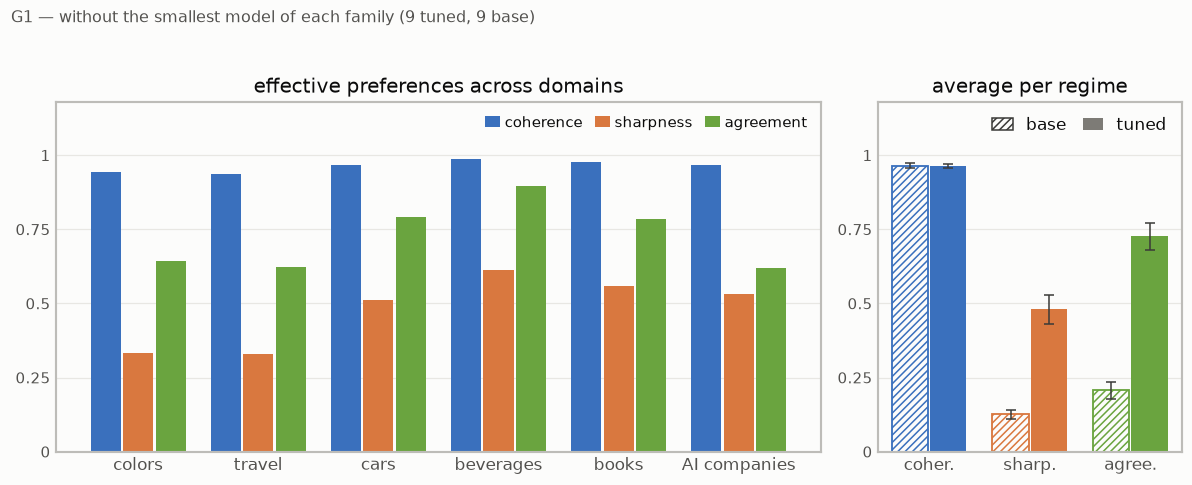

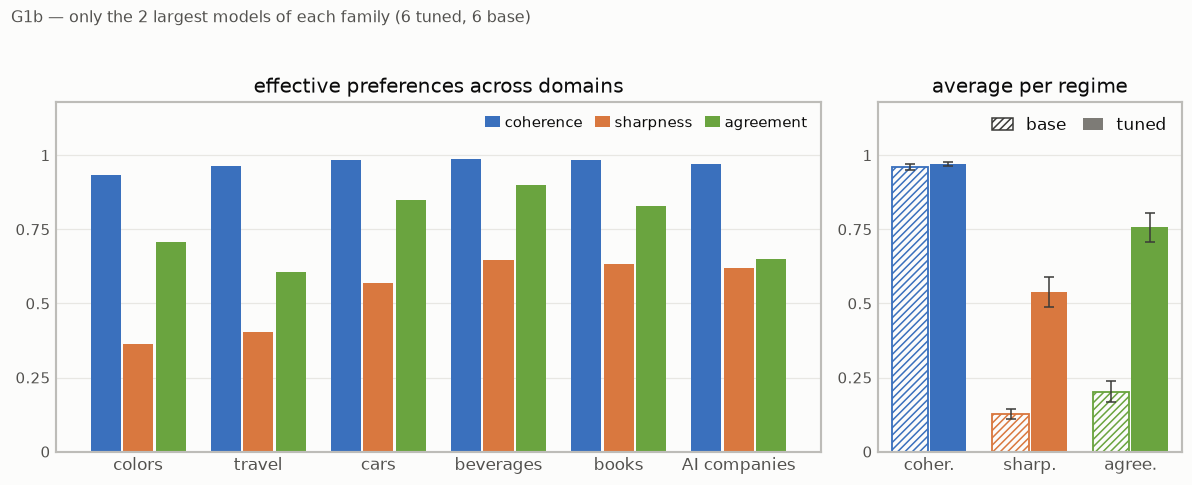

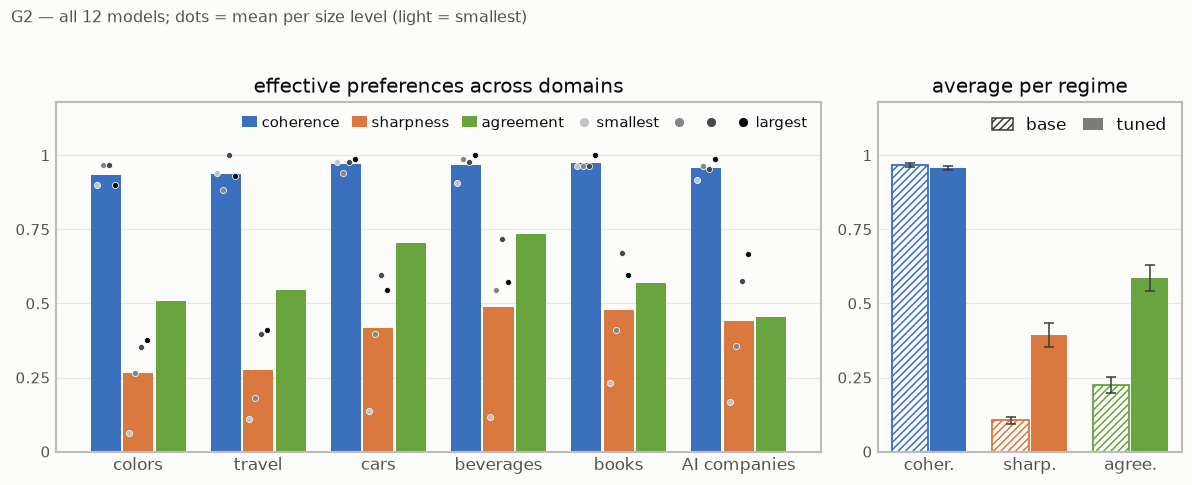

                    all 12           no smallest           2 largest          
                        A1 agreement          A1 agreement        A1 agreement
domain                                                                        
colors                0.26      0.51        0.33      0.64      0.36      0.71
travel_destinations   0.27      0.55        0.33      0.62      0.40      0.61
cars                  0.42      0.70        0.51      0.79      0.57      0.85
beverages             0.49      0.73        0.61      0.90      0.64      0.90
literature_genres     0.48      0.57        0.56      0.78      0.63      0.83
ai_companies          0.44      0.45        0.53      0.62      0.62      0.65
                 all 12  no smallest  2 largest
base A1            0.11         0.13       0.13
base agreement     0.22         0.21       0.20
tuned A1           0.39         0.48       0.54
tuned agreement    0.59         0.73       0.76


In [20]:
def dom_table(ms, doms=DOMS_E):
    """Per-domain coherence / sharpness (mean over ms) and agreement (W across ms)."""
    sub = SH[SH.model.isin(ms) & SH.domain.isin(doms)]
    T = sub.groupby("domain")[["coherence", "A1", "KL-all", "intrinsic"]].mean().loc[doms]
    T["agreement"] = [kendall_w(np.array([rankdata(-BORDA[(*m, d)][RUNS[(*m, d)]["items"]]) for m in ms])) for d in doms]
    return T


def fig_g(tabs, cand="A1", doms=DOMS_E, size_dots=False, fname=None, tag=None):
    """tabs = {"tuned": table, "base": table}; left panel = tuned, right panel = base vs tuned."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(4 + 1.15 * len(doms), 4.2), gridspec_kw={"width_ratios": [0.42 * len(doms), 1]})
    cols = {"coherence": "coherence", "sharpness": cand, "agreement": "agreement"}
    x = np.arange(len(doms))
    T = tabs["tuned"]
    for j, (lab, col) in enumerate(cols.items()):
        xj = x + (j - 1) * 0.27
        a1.bar(xj, T[col].clip(lower=0), 0.25, color=MCOL[lab], label=lab, zorder=2)
        if size_dots and lab != "agreement":
            for tier in range(4):
                ms = [m for m in IT if TIER[m] == tier]
                y = SH[SH.model.isin(ms) & SH.domain.isin(doms)].groupby("domain")[col].mean().loc[doms]
                a1.scatter(xj + (tier - 1.5) * 0.05, y, s=16, color=pale(INK, 0.75 - 0.25 * tier), edgecolor="white",
                           lw=0.5, zorder=4)
    frame(a1)
    a1.set_xticks(x, [DLABEL.get(d, d.replace("_", " ")) for d in doms], fontsize=11)
    h, l = a1.get_legend_handles_labels()
    if size_dots:
        h += [plt.Line2D([], [], marker="o", ls="", color=pale(INK, 0.75 - 0.25 * t), ms=5) for t in range(4)]
        l += ["smallest", "", "", "largest"]
    a1.legend(h, l, frameon=False, ncol=len(h), loc="upper right", fontsize=10, handlelength=1, columnspacing=0.8,
              handletextpad=0.3)
    a1.set_title("effective preferences across domains", fontsize=13)
    for i, (lab, col) in enumerate(cols.items()):
        for j, reg in enumerate(("base", "tuned")):
            v = tabs[reg][col]
            a2.bar(i + (j - 0.5) * 0.38, v.mean(), 0.36, yerr=v.std(ddof=1) / np.sqrt(len(v)), capsize=3,
                   error_kw={"lw": 1, "ecolor": "#3a3a38"}, zorder=2, color=SURFACE if reg == "base" else MCOL[lab],
                   edgecolor=MCOL[lab], hatch="/////" if reg == "base" else None, lw=1.2 if reg == "base" else 0)
    frame(a2)
    a2.set_xticks(range(3), ["coher.", "sharp.", "agree."], fontsize=11)
    a2.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor="#3a3a38", hatch="/////", label="base"),
                       plt.Rectangle((0, 0), 1, 1, facecolor="#7d7b76", label="tuned")],
              frameon=False, fontsize=11, loc="upper right", ncol=2, handlelength=1.2, columnspacing=1)
    a2.set_title("average per regime", fontsize=13)
    if tag:
        fig.suptitle(tag, x=0.01, y=1.04, ha="left", fontsize=10.5, color=INK_MUTED)
    fig.tight_layout()
    if fname:
        fig.savefig(os.path.join(FIGDIR, fname + ".png"), facecolor=SURFACE)
        fig.savefig(os.path.join(FIGDIR, fname + ".pdf"), facecolor=SURFACE)
    plt.show()


ALL = {"tuned": dom_table(IT), "base": dom_table(PT)}
NO_SMALL = {"tuned": dom_table([m for m in IT if TIER[m] > 0]), "base": dom_table([m for m in PT if TIER[m] > 0])}
fig_g(NO_SMALL, fname="G1_without_smallest", tag="G1 — without the smallest model of each family (9 tuned, 9 base)")
BIG2 = {"tuned": dom_table([m for m in IT if TIER[m] >= 2]), "base": dom_table([m for m in PT if TIER[m] >= 2])}
fig_g(BIG2, fname="G1b_two_largest", tag="G1b — only the 2 largest models of each family (6 tuned, 6 base)")
fig_g(ALL, size_dots=True, fname="G2_size_dots", tag="G2 — all 12 models; dots = mean per size level (light = smallest)")
print(pd.concat({"all 12": ALL["tuned"], "no smallest": NO_SMALL["tuned"], "2 largest": BIG2["tuned"]}, axis=1)
      [[(k, c) for k in ("all 12", "no smallest", "2 largest") for c in ("A1", "agreement")]].round(2).to_string())
print(pd.DataFrame({k: {f"{r} {c}": t[r][c].mean() for r in ("base", "tuned") for c in ("A1", "agreement")}
                    for k, t in (("all 12", ALL), ("no smallest", NO_SMALL), ("2 largest", BIG2))}).round(2).to_string())

## H — intrinsic sharpness: the position bias peeled off

A1 averages the two orders in **probability**: `P = ½[σ(m(x,y)) + 1 − σ(m(y,x))]`. A model that says "1" in both
orders gets P ≈ ½ even if it leans to x — the position bias swallows the preference (A1 = what the user **gets**).

**Intrinsic** averages them in **log-odds**: `D = (m(x,y) − m(y,x)) / 2` (the same D as Borda and coherence). With
`m = γ + Δ` (position + preference), D = Δ: the position bias cancels. Certainty `|2σ(D) − 1| = tanh(|D| / 2)`, mean over
all pairs and templates. 0 = no preference, 1 = certain, if the slot were neutral. Assumes the position bias is additive in
log-odds — the same assumption Borda and coherence already make.

- **H1** — the summary figure with intrinsic sharpness, for the three model sets (all 12, without the smallest, 2 largest).
- **H2** — effective (A1) vs intrinsic, per model: where the gap is large, the position bias hid a preference.

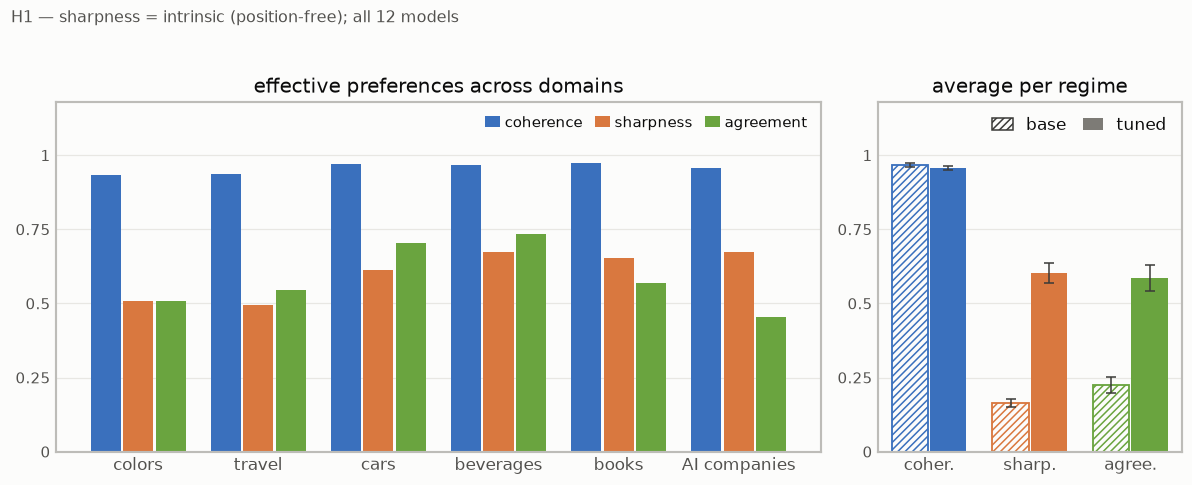

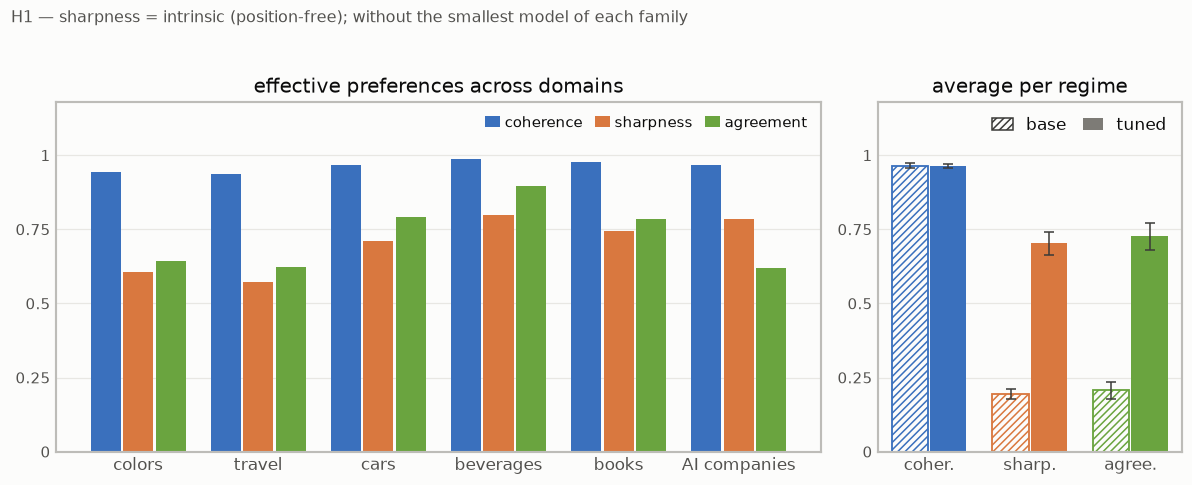

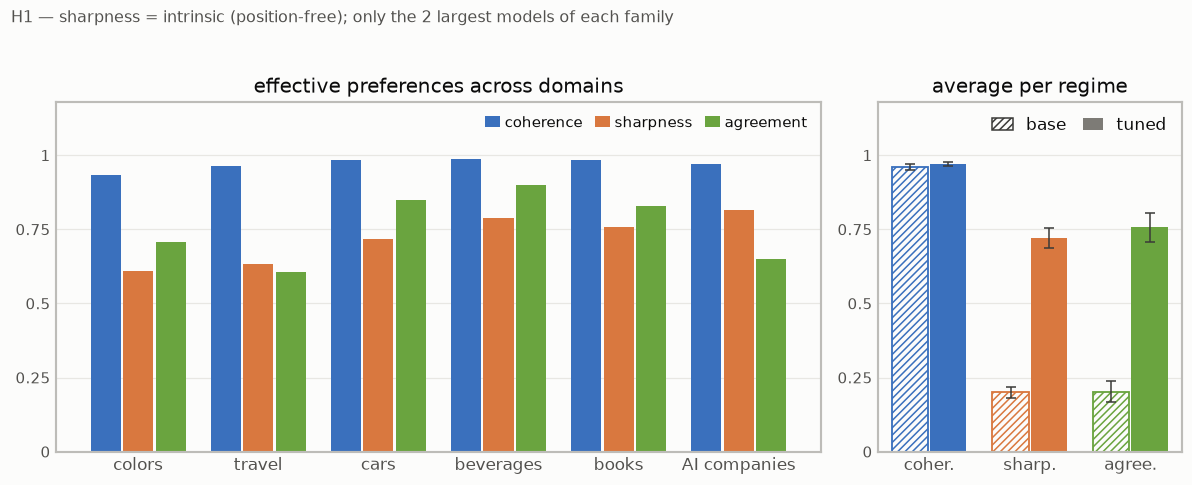

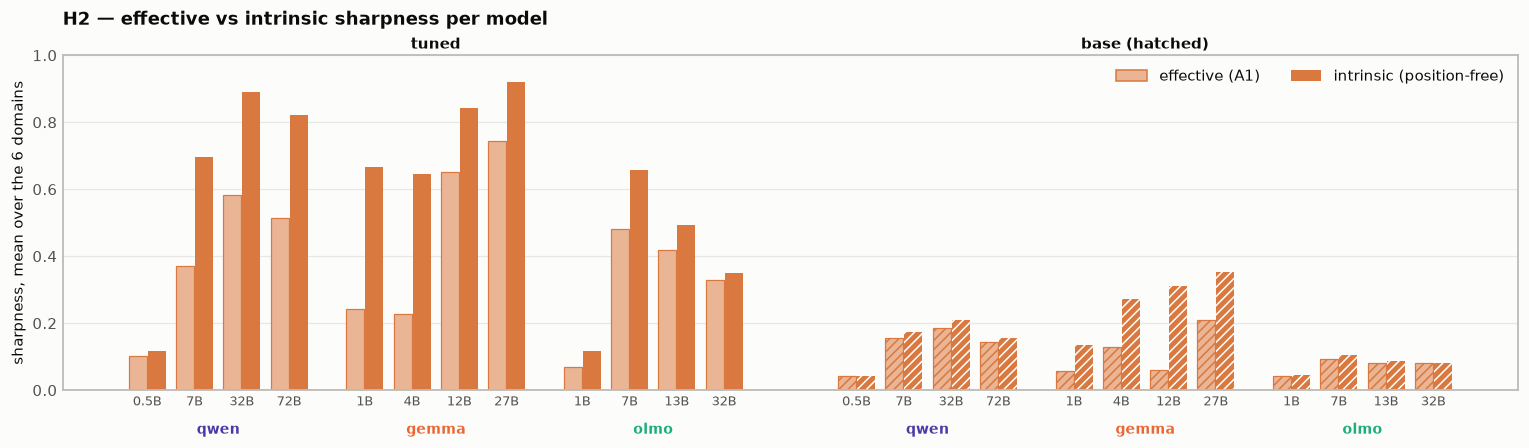

In [21]:
for tabs, name, tag in [(ALL, "all", "all 12 models"), (NO_SMALL, "no_smallest", "without the smallest model of each family"),
                        (BIG2, "two_largest", "only the 2 largest models of each family")]:
    fig_g(tabs, cand="intrinsic", fname=f"H1_intrinsic_{name}", tag=f"H1 — sharpness = intrinsic (position-free); {tag}")

# H2: effective vs intrinsic, per model
fig, ax = plt.subplots(figsize=(14, 4.2))
xs = [i + (i // 4) * 0.6 + (1.2 if i >= 12 else 0) for i in range(len(MODELS))]
for x, m in zip(xs, MODELS):
    sub = SH[(SH.model == m) & SH.domain.isin(DOMS_E)]
    eff, intr = sub["A1"].mean(), sub["intrinsic"].mean()
    ax.bar(x - 0.2, eff, 0.38, color=pale("#d9783f", 0.45), edgecolor="#d9783f", lw=0.8, zorder=2,
           hatch="////" if is_base(m) else None)
    ax.bar(x + 0.2, intr, 0.38, color="#d9783f", zorder=2, hatch="////" if is_base(m) else None, edgecolor="white", lw=0)
box_frame(ax, 1.0)
ax.set_xticks(xs, [f"{m[1]}B" for m in MODELS], fontsize=8.5)
for k, lab in [(1.5, "qwen"), (6.1, "gemma"), (10.7, "olmo")]:
    for off in (0, xs[12] - xs[0]):
        ax.text(k + off, -0.13, lab, transform=ax.get_xaxis_transform(), ha="center", fontsize=9, color=FAM_COL[lab],
                fontweight="bold")
ax.text((xs[0] + xs[11]) / 2, 1.02, "tuned", transform=ax.get_xaxis_transform(), ha="center", fontweight="bold")
ax.text((xs[12] + xs[23]) / 2, 1.02, "base (hatched)", transform=ax.get_xaxis_transform(), ha="center", fontweight="bold")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, facecolor=pale("#d9783f", 0.45), edgecolor="#d9783f", label="effective (A1)"),
                   plt.Rectangle((0, 0), 1, 1, facecolor="#d9783f", label="intrinsic (position-free)")],
          frameon=False, loc="upper right", ncol=2)
ax.set_ylabel("sharpness, mean over the 6 domains")
ax.set_title("H2 — effective vs intrinsic sharpness per model", loc="left", fontweight="bold", pad=20)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "H2_effective_vs_intrinsic.png"), facecolor=SURFACE)
plt.show()